# House Prices: End-to-End Analysis

Predicting the sale price of houses in Ames, Iowa (Kaggle: *House Prices: Advanced Regression Techniques*).

This notebook brings the whole project together, from the raw CSV files to `submission.csv`:

| Part | Sections | Content |
|---|---|---|
| Data | 1–5 | Metric, reading pitfalls, cleaning rules, data roles and outliers, EDA |
| Pipeline | 6–7 | Feature encoding, filling `LotFrontage` and `MSZoning`, shared preprocessing |
| Models | 8–11 | Seven candidate models and blends, cross-validation, bias at the extremes, holdout |
| Errors | 12–13 | Which houses cause the error, special cases, down-weighting unusual sales |
| Result | 14–15 | What drives the price, final model, submission, summary |

**One rule decides everything:** the cross-validated RMSLE (the competition metric) on the same five folds of the training data. Candidates within 0.0002 of the best are a tie, and a tie goes to the simpler one. A separate 20% holdout is used once, only to confirm the result.

In [1]:
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.optimize import minimize
from scipy.stats import skew

from sklearn.base import BaseEstimator, TransformerMixin, RegressorMixin, clone
from sklearn.compose import ColumnTransformer, TransformedTargetRegressor, make_column_selector
from sklearn.ensemble import RandomForestRegressor, RandomForestClassifier, GradientBoostingRegressor
from sklearn.impute import SimpleImputer
from sklearn.inspection import permutation_importance
from sklearn.linear_model import Lasso, Ridge, ElasticNet, LassoCV
from sklearn.metrics import mean_squared_error, make_scorer
from sklearn.model_selection import train_test_split, KFold, GridSearchCV, cross_val_predict
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler, FunctionTransformer
from xgboost import XGBRegressor

# Harmless joblib notice raised by parallel cross-validation with sample weights
warnings.filterwarnings("ignore", message=".*sklearn.utils.parallel.delayed.*")

DATA_DIR = Path(".")
RANDOM_STATE = 42

# Okabe-Ito colour-blind-safe palette, one fixed colour per model family
MODEL_COLORS = {
    "Random Forest": "#0072B2",
    "Lasso": "#009E73",
    "Ridge": "#56B4E9",
    "ElasticNet": "#009E73",
    "Gradient Boosting": "#E69F00",
    "XGBoost": "#000000",
    "Two-stage (hard)": "#CC79A7",
    "Two-stage (soft)": "#CC79A7",
    "Blend": "#D55E00",
}
MAIN_COLOR, ACCENT_COLOR = "#0072B2", "#D55E00"
money = plt.FuncFormatter(lambda v, _: f"${v/1000:,.0f}k")
plt.rcParams.update({"axes.grid": True, "grid.alpha": 0.3, "axes.spines.top": False, "axes.spines.right": False})

## 1. Problem and metric

**Target:** `SalePrice` in US dollars, a regression problem. 1,460 houses have known prices (`train.csv`); 1,459 do not (`test.csv`) and are scored by Kaggle.

**Metric:** Kaggle scores the root mean squared error between the *logarithms* of predicted and actual prices (RMSLE):

$$\text{RMSLE} = \sqrt{\frac{1}{n}\sum_{i=1}^{n}\left(\log(1+\hat{y}_i) - \log(1+y_i)\right)^2}$$

Because $\log a - \log b = \log(a/b)$, the metric measures **relative** error: an RMSLE of 0.12 means predictions are typically about 12% away from the true price. A \$20,000 error on a \$100,000 house counts far more than the same error on a \$500,000 house. Every model below is therefore trained on `log1p(SalePrice)`.

In [2]:
def rmse_score(y_true, y_pred):
    """Return RMSE in the same units as the target."""
    return np.sqrt(mean_squared_error(y_true, y_pred))


def rmsle_score(y_true, y_pred):
    """Return RMSE between log prices (the competition metric)."""
    return rmse_score(np.log1p(y_true), np.log1p(y_pred))


rmsle_scorer = make_scorer(rmsle_score, greater_is_better=False)

# The same $20,000 error on a cheap and an expensive house
examples = pd.DataFrame({"Actual price": [100_000, 500_000], "Predicted price": [120_000, 520_000]})
examples["Error (%)"] = (examples["Predicted price"] / examples["Actual price"] - 1) * 100
examples["Log error"] = np.abs(np.log1p(examples["Predicted price"]) - np.log1p(examples["Actual price"]))
examples.round(3)

,Actual price,Predicted price,Error (%),Log error
0,100000,120000,20.0,0.182
1,500000,520000,4.0,0.039


## 2. Reading the data: the string `"None"`

By default, `pandas.read_csv` turns both `"NA"` and `"None"` into missing values. In this dataset they mean different things:

- `"NA"` is the data dictionary's code for "not present" (for example, no pool) or a genuinely missing value.
- `"None"` is a real category in `MasVnrType`: **the house has no masonry veneer**.

`load_house_data()` tells pandas that only empty fields and `"NA"` mean missing.

In [3]:
def load_house_data(file_path):
    """Read a competition CSV while keeping "None" as a real category."""
    return pd.read_csv(file_path, keep_default_na=False, na_values=["", "NA"])


train_raw = load_house_data(DATA_DIR / "train.csv")
test_raw = load_house_data(DATA_DIR / "test.csv")
print("train.csv:", train_raw.shape, "  test.csv:", test_raw.shape)

pd.DataFrame({
    "pandas default": pd.read_csv(DATA_DIR / "train.csv")["MasVnrType"].value_counts(dropna=False),
    "load_house_data": train_raw["MasVnrType"].value_counts(dropna=False),
}).fillna(0).astype(int)

train.csv: (1460, 81)   test.csv: (1459, 80)


,pandas default,load_house_data
MasVnrType,,
BrkCmn,15,15
BrkFace,445,445
None,0,864
Stone,128,128
NaN,872,8


With default reading, 864 valid `"None"` records would become missing and be indistinguishable from the 8 truly missing ones.

## 3. Cleaning rules

### Missing values in the training data

In [4]:
missing_summary = pd.DataFrame({
    "Missing (train)": train_raw.isna().sum(),
    "Missing (%)": train_raw.isna().mean() * 100,
    "Missing (test)": test_raw.isna().sum(),
})
missing_summary = missing_summary.loc[missing_summary["Missing (train)"] > 0].sort_values("Missing (train)", ascending=False)
missing_summary.style.format({"Missing (%)": "{:.1f}", "Missing (test)": "{:.0f}"})

,Missing (train),Missing (%),Missing (test)
PoolQC,1453,99.5,1456
MiscFeature,1406,96.3,1408
Alley,1369,93.8,1352
Fence,1179,80.8,1169
FireplaceQu,690,47.3,730
LotFrontage,259,17.7,227
GarageType,81,5.5,76
GarageYrBlt,81,5.5,78
GarageQual,81,5.5,78
GarageFinish,81,5.5,78


A missing value can mean three different things, and each needs its own treatment. Filling every gap with a median would erase that difference.

| Meaning | Example | Treatment |
|---|---|---|
| **Absence** | `PoolQC` is missing because there is no pool | An explicit category such as `"NoPool"` |
| **Unknown** | The house has a basement, but `BsmtFinType2` was not recorded | The category `"Unknown"`, or a learned estimate for numbers |
| **Not applicable** | A house without a garage has no garage year | The house's own year, plus the indicator `HasGarage = 0` |

**Absence is confirmed, not assumed.** The dictionary says `NA` in `PoolQC` means "no pool", but the rule also checks a related measurement:

| Columns | Absence is confirmed when | Label |
|---|---|---|
| `PoolQC` | `PoolArea == 0` | `"NoPool"` |
| `FireplaceQu` | `Fireplaces == 0` | `"NoFireplace"` |
| Garage categories | `GarageArea == 0` and `GarageCars == 0` | `"NoGarage"` |
| Basement categories | `TotalBsmtSF == 0`, or **every** basement field is missing | `"NoBasement"` |
| `Alley`, `Fence`, `MiscFeature` | No related measurement; the dictionary defines `NA` as absence | `"NoAlley"`, `"NoFence"`, `"NoMiscFeature"` |

If a facility exists, or its measurement is itself missing, the category becomes `"Unknown"` instead.

**Other rules:**

| Rule | Reason |
|---|---|
| A house without a basement gets `0` for missing basement areas and basement bathrooms | Test house `Id = 2121` has every basement field missing, and `Id = 2189` has no basement but missing bathroom counts. Without this rule they would receive the median basement (about 1,000 sq ft). |
| A house without a garage gets `GarageYrBlt = YearBuilt` | A linear model would read a placeholder `0` as the year 0. `HasGarage` still marks the absence. |
| A garage year more than one year after the sale is a typo and becomes `YearBuilt` | Test house `Id = 2593` has `GarageYrBlt = 2207`. One year after the sale is allowed: new houses (`Id = 2550`) are often sold before they are finished. |
| Contradictory masonry records are flagged with `VeneerConflict` | `MasVnrType = "None"` with a positive area: the type becomes `"Unknown"`. A named veneer with zero area: both values are kept. The flag is for auditing only, not a predictor. |

Every rule reads **one house's own values** and learns nothing from the dataset as a whole. Applying them to the test set therefore cannot leak information.

In [5]:
BASEMENT_NUMBERS = ["BsmtFinSF1", "BsmtFinSF2", "BsmtUnfSF", "TotalBsmtSF", "BsmtFullBath", "BsmtHalfBath"]
BASEMENT_CATEGORIES = ["BsmtQual", "BsmtCond", "BsmtExposure", "BsmtFinType1", "BsmtFinType2"]


def clean_house_data(df):
    """Apply fixed, row-by-row cleaning rules from the data dictionary.

    No statistics are learned here, so the same function can be applied
    to the training data and to unseen test data without leakage.
    """
    result = df.copy()

    # Features whose missing values mean absence according to the dictionary
    absence_labels = {"Alley": "NoAlley", "Fence": "NoFence", "MiscFeature": "NoMiscFeature"}
    for column, label in absence_labels.items():
        result[column] = result[column].fillna(label)

    # Confirm absence using related numerical features
    # A missing measurement is not treated as confirmed absence
    no_pool = result["PoolArea"].eq(0)
    no_fireplace = result["Fireplaces"].eq(0)
    no_garage = result["GarageArea"].eq(0) & result["GarageCars"].eq(0)
    no_basement = (
        result["TotalBsmtSF"].eq(0)
        | result[BASEMENT_NUMBERS + BASEMENT_CATEGORIES].isna().all(axis=1)
    )

    facility_groups = [
        (["PoolQC"], no_pool, "NoPool"),
        (["FireplaceQu"], no_fireplace, "NoFireplace"),
        (["GarageType", "GarageFinish", "GarageQual", "GarageCond"], no_garage, "NoGarage"),
        (BASEMENT_CATEGORIES, no_basement, "NoBasement"),
    ]
    for columns, absence_mask, label in facility_groups:
        for column in columns:
            result.loc[absence_mask & result[column].isna(), column] = label
            # Remaining missing values mean information is unknown
            result[column] = result[column].fillna("Unknown")

    # No basement means zero basement area and no basement bathrooms
    for column in BASEMENT_NUMBERS:
        result.loc[no_basement & result[column].isna(), column] = 0

    # Garage year: a typo (more than a year after the sale) or no garage
    # means the house's own year is used
    result["HasGarage"] = (~no_garage).astype(int)
    use_house_year = no_garage | result["GarageYrBlt"].gt(result["YrSold"] + 1)
    result.loc[use_house_year, "GarageYrBlt"] = result.loc[use_house_year, "YearBuilt"]

    # Flag contradictory masonry records in both directions
    area_without_type = result["MasVnrType"].eq("None") & result["MasVnrArea"].gt(0)
    type_without_area = (
        result["MasVnrType"].notna() & result["MasVnrType"].ne("None") & result["MasVnrArea"].eq(0)
    )
    result["VeneerConflict"] = (area_without_type | type_without_area).astype(int)
    result.loc[area_without_type, "MasVnrType"] = "Unknown"
    result["MasVnrType"] = result["MasVnrType"].replace({"None": "NoVeneer"}).fillna("Unknown")

    # Explicit "no veneer" means zero area; other unknown areas are imputed later
    result["MasVnrArea"] = result["MasVnrArea"].fillna(result["MasVnrType"].map({"NoVeneer": 0.0}))

    return result


train_clean = clean_house_data(train_raw)
test_clean = clean_house_data(test_raw)

### The rules applied to real houses

In [6]:
def before_after(raw, clean, ids, columns):
    """Show selected columns for selected houses before and after cleaning."""
    return pd.concat({
        "Before": raw.set_index("Id").loc[ids, columns],
        "After": clean.set_index("Id").loc[ids, columns],
    }, axis=1)


print("A house without a garage")
display(before_after(train_raw, train_clean, [40], ["GarageType", "GarageYrBlt", "GarageArea"]))

print("A basement exists, but one rating is missing: 'Unknown', not 'NoBasement'")
display(before_after(train_raw, train_clean, [333], ["BsmtFinType2", "BsmtFinSF2", "TotalBsmtSF"]))

print("Test houses with no basement information at all, or missing basement bathrooms")
display(before_after(test_raw, test_clean, [2121, 2189], ["BsmtQual", "TotalBsmtSF", "BsmtFullBath"]))

print("Test garage years after the sale: a typo (2593) and a house sold before completion (2550)")
display(before_after(test_raw, test_clean, [2550, 2593], ["YearBuilt", "YrSold", "GarageYrBlt"]))

print("Contradictory masonry records")
conflict_ids = train_clean.loc[train_clean["VeneerConflict"].eq(1), "Id"].tolist()
display(before_after(train_raw, train_clean, conflict_ids, ["MasVnrType", "MasVnrArea"]))

A house without a garage


Before                             After                       
   GarageType GarageYrBlt GarageArea GarageType GarageYrBlt GarageArea
Id                                                                    
40        NaN         NaN          0   NoGarage      1955.0          0

A basement exists, but one rating is missing: 'Unknown', not 'NoBasement'


Before                               After                       
    BsmtFinType2 BsmtFinSF2 TotalBsmtSF BsmtFinType2 BsmtFinSF2 TotalBsmtSF
Id                                                                         
333          NaN        479        3206      Unknown        479        3206

Test houses with no basement information at all, or missing basement bathrooms


Before                                After                         
     BsmtQual TotalBsmtSF BsmtFullBath    BsmtQual TotalBsmtSF BsmtFullBath
Id                                                                         
2121      NaN         NaN          NaN  NoBasement         0.0          0.0
2189      NaN         0.0          NaN  NoBasement         0.0          0.0

Test garage years after the sale: a typo (2593) and a house sold before completion (2550)


Before                        After                   
     YearBuilt YrSold GarageYrBlt YearBuilt YrSold GarageYrBlt
Id                                                            
2550      2008   2007      2008.0      2008   2007      2008.0
2593      2006   2007      2207.0      2006   2007      2006.0

Contradictory masonry records


Before                 After           
     MasVnrType MasVnrArea MasVnrType MasVnrArea
Id                                              
625        None      288.0    Unknown      288.0
689     BrkFace        0.0    BrkFace        0.0
774        None        1.0    Unknown        1.0
1231       None        1.0    Unknown        1.0
1242      Stone        0.0      Stone        0.0
1301       None      344.0    Unknown      344.0
1335       None      312.0    Unknown      312.0

### What is still missing after cleaning

The remaining gaps need a **learned** value, such as a median. They are filled inside the model pipeline (section 7), where every value is learned from training data only.

In [7]:
remaining = pd.DataFrame({
    "Missing (train)": train_clean.isna().sum(),
    "Missing (test)": test_clean.isna().sum(),
}).fillna(0).astype(int)
remaining.loc[remaining.sum(axis=1) > 0]

,Missing (train),Missing (test)
Electrical,1,0
Exterior1st,0,1
Exterior2nd,0,1
Functional,0,2
GarageArea,0,1
GarageCars,0,1
GarageYrBlt,0,2
KitchenQual,0,1
LotFrontage,259,227
MSZoning,0,4


- `LotFrontage` is the only large gap (18% of houses). Section 7 tests how to fill it.
- `MSZoning` is missing for 4 test houses, 3 of them in `IDOTRR`. Section 7 fills it from the house's neighborhood.
- `MasVnrArea` (type also unknown) and the single-house gaps are filled with training medians or the most common category.

## 4. Data roles and outliers

| Data | Has prices? | Used for | Never used for |
|---|---|---|---|
| `train_part` (80% of `train.csv`) | Yes | Fitting and **every** choice, through 5-fold cross-validation | — |
| `valid_part` (20% of `train.csv`) | Yes | One final check of the chosen model | Fitting, tuning, or choosing |
| `test.csv` | No | The submission | Anything that influences the model |

**Leakage test:** *could one house be processed on its own and give the same result?* If yes (the cleaning rules), the step cannot leak. If not (medians, category lists, scaling), it must be learned inside the pipeline from training data only.

**Outliers.** The dataset's author notes houses over 4,000 sq ft in the full Ames data: partial sales that "likely don't represent actual market values" and very large houses "priced relatively appropriately" (De Cock, *Journal of Statistics Education* 19(3), 2011, [data documentation](http://jse.amstat.org/v19n3/decock/DataDocumentation.txt)). Only the two whose price contradicts their size (Ids 524 and 1299) are removed, and only from `train_part`; the holdout stays untouched, like unseen data.

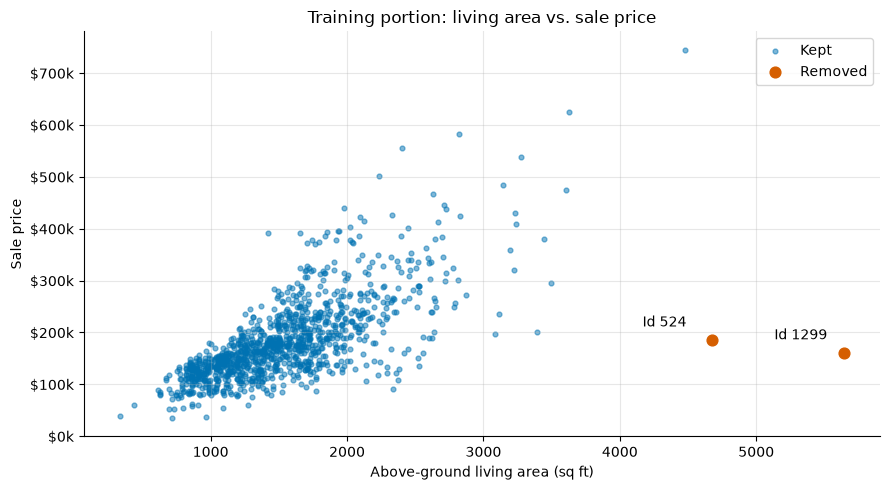

Removed from training (Id): [524, 1299]
train_part: 1166   valid_part: 292   test: 1459


In [8]:
train_part, valid_part = train_test_split(train_clean, test_size=0.2, random_state=RANDOM_STATE)


def is_outlier(df):
    """Very large houses sold at unusually low prices (documented by the dataset author)."""
    return df["GrLivArea"].gt(4000) & df["SalePrice"].lt(300000)


outliers = is_outlier(train_part)
fig, ax = plt.subplots(figsize=(9, 5))
ax.scatter(train_part.loc[~outliers, "GrLivArea"], train_part.loc[~outliers, "SalePrice"],
           s=12, alpha=0.5, color=MAIN_COLOR, label="Kept")
ax.scatter(train_part.loc[outliers, "GrLivArea"], train_part.loc[outliers, "SalePrice"],
           s=60, color=ACCENT_COLOR, label="Removed")
for _, row in train_part.loc[outliers].iterrows():
    ax.annotate(f"Id {row['Id']}", (row["GrLivArea"], row["SalePrice"]), xytext=(-50, 10), textcoords="offset points")
ax.set_title("Training portion: living area vs. sale price")
ax.set_xlabel("Above-ground living area (sq ft)")
ax.set_ylabel("Sale price")
ax.yaxis.set_major_formatter(money)
ax.legend()
plt.tight_layout()
plt.show()

print("Removed from training (Id):", train_part.loc[outliers, "Id"].tolist())
train_part = train_part.loc[~outliers].copy()
print(f"train_part: {len(train_part)}   valid_part: {len(valid_part)}   test: {len(test_clean)}")

## 5. EDA: the target

Exploration uses `train_part` only, so the holdout cannot influence any design choice.

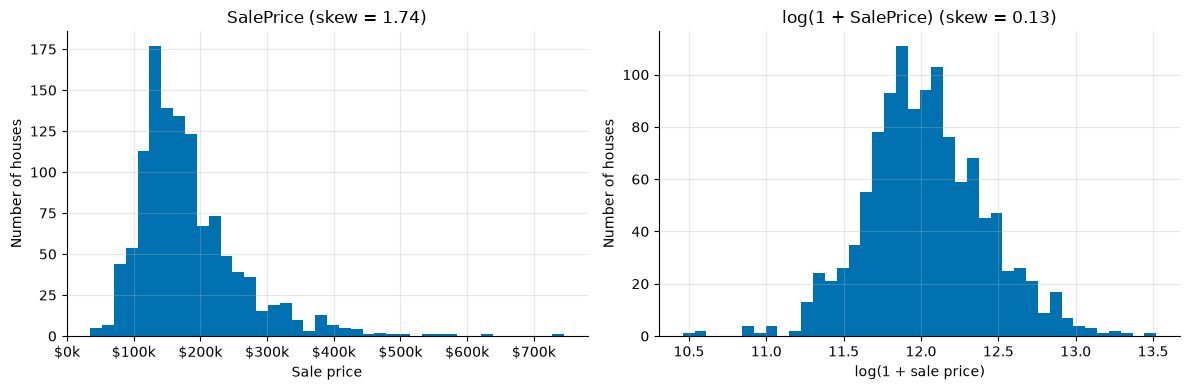

In [9]:
log_price = np.log1p(train_part["SalePrice"])

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].hist(train_part["SalePrice"], bins=40, color=MAIN_COLOR)
axes[0].set_title(f"SalePrice (skew = {train_part['SalePrice'].skew():.2f})")
axes[0].set_xlabel("Sale price")
axes[0].xaxis.set_major_formatter(money)
axes[1].hist(log_price, bins=40, color=MAIN_COLOR)
axes[1].set_title(f"log(1 + SalePrice) (skew = {log_price.skew():.2f})")
axes[1].set_xlabel("log(1 + sale price)")
for ax in axes:
    ax.set_ylabel("Number of houses")
plt.tight_layout()
plt.show()

Prices are right-skewed: most houses cost \$100k–\$250k, with a long tail of expensive ones. On the log scale the distribution is nearly symmetric. Together with the metric, this is why every model learns `log1p(SalePrice)`.

No feature-by-feature analysis is done to choose predictors. Regularised models decide which features matter (section 8), and that choice is checked by cross-validation rather than by eye.

## 6. Feature encoding

`make_features()` prepares the predictors with fixed rules:

- Drops `Id`, the target, and the audit column `VeneerConflict`.
- Treats `MSSubClass` as a category: it is a dwelling-type code (20, 60, ...), not a quantity.
- Converts rating columns into ordered numbers using the dictionary's own scales (`Po < Fa < TA < Gd < Ex` and similar). Absence becomes 0, and `"Unknown"` becomes missing, to be imputed later. A linear model can then use "better quality" as one direction instead of five unrelated categories.

In [10]:
QUALITY_SCALE = {"Po": 1, "Fa": 2, "TA": 3, "Gd": 4, "Ex": 5}
ABSENCE_ZERO = {label: 0 for label in ["NoBasement", "NoGarage", "NoFireplace", "NoPool"]}
ORDINAL_MAPS = {
    **{column: {**QUALITY_SCALE, **ABSENCE_ZERO} for column in [
        "ExterQual", "ExterCond", "BsmtQual", "BsmtCond", "HeatingQC",
        "KitchenQual", "FireplaceQu", "GarageQual", "GarageCond", "PoolQC"
    ]},
    "BsmtExposure": {"No": 1, "Mn": 2, "Av": 3, "Gd": 4, **ABSENCE_ZERO},
    "BsmtFinType1": {"Unf": 1, "LwQ": 2, "Rec": 3, "BLQ": 4, "ALQ": 5, "GLQ": 6, **ABSENCE_ZERO},
    "BsmtFinType2": {"Unf": 1, "LwQ": 2, "Rec": 3, "BLQ": 4, "ALQ": 5, "GLQ": 6, **ABSENCE_ZERO},
    "GarageFinish": {"Unf": 1, "RFn": 2, "Fin": 3, **ABSENCE_ZERO},
}

# Identifiers, targets, and audit columns are not predictors
NON_FEATURE_COLS = ["Id", "SalePrice", "VeneerConflict"]


def make_features(df):
    """Select predictors and encode them with fixed rules."""
    X = df.drop(columns=NON_FEATURE_COLS, errors="ignore").copy()
    X["MSSubClass"] = X["MSSubClass"].astype(str)
    for column, mapping in ORDINAL_MAPS.items():
        X[column] = X[column].map(mapping).astype(float)
    return X


X_train, y_train = make_features(train_part), train_part["SalePrice"]
X_valid, y_valid = make_features(valid_part), valid_part["SalePrice"]
X_test = make_features(test_clean)
assert list(X_test.columns) == list(X_train.columns)

# One set of folds for every comparison in this notebook
cv_folds = list(KFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE).split(X_train))


def fold_rmsle(predictions, y=y_train, folds=cv_folds):
    """Mean and standard deviation of RMSLE across the shared CV folds."""
    scores = [rmsle_score(y.iloc[valid], predictions[valid]) for _, valid in folds]
    return np.mean(scores), np.std(scores)


print("Predictor columns:", X_train.shape[1])

Predictor columns: 80


## 7. The pipeline

Every model uses the same pipeline. All steps that learn something are fitted on training folds only:

| Step | What it does |
|---|---|
| `LotFrontageImputer` | Fills missing `LotFrontage` (tested below) |
| `GroupModeImputer` | Fills missing `MSZoning` with the most common zone of the house's neighborhood |
| Numbers | Median imputer → `log1p` for strongly skewed columns → standardisation |
| Categories | Most-frequent imputer → one-hot encoding |
| Model | Trained on `log1p(price)`; predictions are converted back to dollars |

Log-transforming skewed columns and standardising matter for linear models: the penalty treats every coefficient alike, so features need a common scale. Tree models are unaffected by either step, so one shared preprocessor keeps the comparison fair.

### Filling missing `LotFrontage`

`LotFrontage` (street-facing width of the lot) is missing for about 18% of houses. Three methods are compared:

| Method | How it fills a missing value |
|---|---|
| Global median | One number for every house |
| Neighborhood median | Median of houses in the same neighborhood |
| Model-based | A small Random Forest predicts frontage from `log(LotArea)`, `Neighborhood`, `BldgType`, `LotConfig`, `LotShape`, `MSSubClass` |

The model-based method uses lot area because frontage × depth ≈ area: the relationship is geometric. It never uses `SalePrice`, which is unknown for test houses.

Two tests: (1) **hide-and-guess**: hide known frontage values and measure how close each method's guess is; (2) **effect on the final model**: plug each method into a real pipeline and compare CV RMSLE. Only the second decides.

In [11]:
FRONTAGE_CATS = ["Neighborhood", "BldgType", "LotConfig", "LotShape", "MSSubClass"]


class LotFrontageImputer(BaseEstimator, TransformerMixin):
    """Fill LotFrontage using values learned from the training data only.

    method: "global", "neighborhood", or "model"
    add_indicator: add a 0/1 column marking originally missing values
    """

    def __init__(self, method="model", add_indicator=False):
        self.method = method
        self.add_indicator = add_indicator

    def fit(self, X, y=None):
        observed = X.loc[X["LotFrontage"].notna()]
        self.global_median_ = observed["LotFrontage"].median()

        if self.method == "neighborhood":
            self.by_neighborhood_ = observed.groupby("Neighborhood")["LotFrontage"].median()
        elif self.method == "model":
            self.model_ = Pipeline([
                ("encode", ColumnTransformer([
                    ("area", FunctionTransformer(np.log), ["LotArea"]),
                    ("cats", OneHotEncoder(handle_unknown="ignore"), FRONTAGE_CATS),
                ])),
                ("forest", RandomForestRegressor(
                    n_estimators=300, min_samples_leaf=3, random_state=RANDOM_STATE, n_jobs=-1
                )),
            ])
            self.model_.fit(observed[["LotArea"] + FRONTAGE_CATS], observed["LotFrontage"])
        return self

    def estimate(self, X):
        """Estimated frontage for every row of X."""
        if self.method == "neighborhood":
            return X["Neighborhood"].map(self.by_neighborhood_).fillna(self.global_median_).to_numpy()
        if self.method == "model":
            return self.model_.predict(X[["LotArea"] + FRONTAGE_CATS])
        return np.full(len(X), self.global_median_)

    def transform(self, X):
        result = X.copy()
        missing = result["LotFrontage"].isna()
        if self.add_indicator:
            result["LotFrontage_missing"] = missing.astype(int)
        if missing.any():
            result.loc[missing, "LotFrontage"] = self.estimate(result.loc[missing])
        return result


class GroupModeImputer(BaseEstimator, TransformerMixin):
    """Fill a categorical column with its most common value within a group."""

    def __init__(self, column="MSZoning", group="Neighborhood"):
        self.column = column
        self.group = group

    def fit(self, X, y=None):
        observed = X.dropna(subset=[self.column])
        self.by_group_ = observed.groupby(self.group)[self.column].agg(lambda s: s.mode().iloc[0])
        self.overall_ = observed[self.column].mode().iloc[0]
        return self

    def transform(self, X):
        result = X.copy()
        missing = result[self.column].isna()
        result.loc[missing, self.column] = (
            result.loc[missing, self.group].map(self.by_group_).fillna(self.overall_)
        )
        return result


class SkewedLogTransformer(BaseEstimator, TransformerMixin):
    """Apply log1p to columns that were strongly right-skewed in the training data."""

    def __init__(self, threshold=0.75):
        self.threshold = threshold

    def fit(self, X, y=None):
        X = np.asarray(X, dtype=float)
        is_binary = np.array([len(np.unique(column)) <= 2 for column in X.T])
        self.log_columns_ = (skew(X, axis=0) > self.threshold) & (X.min(axis=0) >= 0) & ~is_binary
        return self

    def transform(self, X):
        X = np.array(X, dtype=float, copy=True)
        X[:, self.log_columns_] = np.log1p(X[:, self.log_columns_])
        return X


def make_preprocessor():
    numeric = Pipeline([
        ("impute", SimpleImputer(strategy="median")),
        ("log_skewed", SkewedLogTransformer()),
        ("scale", StandardScaler()),
    ])
    categorical = Pipeline([
        ("impute", SimpleImputer(strategy="most_frequent")),
        ("encode", OneHotEncoder(handle_unknown="ignore", sparse_output=False)),
    ])
    return ColumnTransformer([
        ("numeric", numeric, make_column_selector(dtype_include=np.number)),
        ("categorical", categorical, make_column_selector(dtype_exclude=np.number)),
    ])


def make_pipeline(regressor, frontage_imputer=None):
    """Full pipeline: imputers -> preprocessing -> model trained on log prices."""
    return Pipeline([
        ("frontage", frontage_imputer if frontage_imputer is not None else clone(BEST_FRONTAGE_IMPUTER)),
        ("zoning", GroupModeImputer("MSZoning", "Neighborhood")),
        ("preprocess", make_preprocessor()),
        ("model", TransformedTargetRegressor(regressor=regressor, func=np.log1p, inverse_func=np.expm1)),
    ])


def oof_predict(pipeline, n_jobs=1, sample_weight=None):
    """Out-of-fold predictions on train_part using the shared folds."""
    params = None if sample_weight is None else {"model__sample_weight": sample_weight}
    return cross_val_predict(pipeline, X_train, y_train, cv=cv_folds, n_jobs=n_jobs, params=params)

**Test 1: hide-and-guess.** Only houses with a known frontage are used: in each fold, the imputer is fitted on four fifths of them and guesses the hidden fifth.

In [12]:
known = X_train.loc[X_train["LotFrontage"].notna()].reset_index(drop=True)

guess_errors = {}
for method in ["global", "neighborhood", "model"]:
    fold_errors = []
    for fit_rows, hidden_rows in KFold(5, shuffle=True, random_state=RANDOM_STATE).split(known):
        imputer = LotFrontageImputer(method=method).fit(known.iloc[fit_rows])
        guesses = imputer.estimate(known.iloc[hidden_rows])
        fold_errors.append(np.mean(np.abs(guesses - known["LotFrontage"].iloc[hidden_rows])))
    guess_errors[method] = fold_errors

pd.DataFrame({
    "Mean absolute error (ft)": {m: np.mean(e) for m, e in guess_errors.items()},
    "Fold std (ft)": {m: np.std(e) for m, e in guess_errors.items()},
}).rename(index={
    "global": "Global median", "neighborhood": "Neighborhood median", "model": "Model-based",
}).sort_values("Mean absolute error (ft)").round(2)

,Mean absolute error (ft),Fold std (ft)
Model-based,9.38,1.12
Neighborhood median,13.45,0.94
Global median,16.70,0.68


**Test 2: effect on the final model.** Each method is plugged into a Random Forest and a Lasso pipeline. Missing frontage is also **not random** (about half of cul-de-sac lots have no frontage recorded, against 13% of inside lots), so a version with a 0/1 `LotFrontage_missing` column is tested too.

In [13]:
print("Share of houses with missing frontage, by lot configuration:")
print(X_train.groupby("LotConfig")["LotFrontage"].apply(lambda s: s.isna().mean()).round(2).to_dict())

frontage_options = {
    "Neighborhood median": LotFrontageImputer("neighborhood"),
    "Model-based": LotFrontageImputer("model"),
    "Model-based + missing indicator": LotFrontageImputer("model", add_indicator=True),
}
probe_models = {
    "Random Forest": RandomForestRegressor(n_estimators=300, max_features=0.33, random_state=RANDOM_STATE, n_jobs=-1),
    "Lasso": LassoCV(alphas=50, cv=5, max_iter=50_000, random_state=RANDOM_STATE),
}

rows = []
for option_name, imputer in frontage_options.items():
    row = {"Filling method": option_name}
    for model_name, model in probe_models.items():
        row[f"{model_name} CV RMSLE"] = fold_rmsle(oof_predict(make_pipeline(clone(model), clone(imputer))))[0]
    rows.append(row)

frontage_results = pd.DataFrame(rows).set_index("Filling method")
frontage_results["Average"] = frontage_results.mean(axis=1)
frontage_results = frontage_results.sort_values("Average")

BEST_FRONTAGE_NAME = frontage_results.index[0]
BEST_FRONTAGE_IMPUTER = frontage_options[BEST_FRONTAGE_NAME]
print("Selected:", BEST_FRONTAGE_NAME)
frontage_results.round(4)

Share of houses with missing frontage, by lot configuration:
{'Corner': 0.25, 'CulDSac': 0.51, 'FR2': 0.32, 'FR3': 0.0, 'Inside': 0.13}


Selected: Model-based


,Random Forest CV RMSLE,Lasso CV RMSLE,Average
Filling method,,,
Model-based,0.1311,0.1106,0.1208
Model-based + missing indicator,0.1313,0.1106,0.1210
Neighborhood median,0.1317,0.1107,0.1212


**Result.** The model-based method guesses frontage about 30% more accurately than neighborhood medians, but its effect on price predictions is far smaller than the variation between folds (about 0.004). The missing indicator does not help. The method with the best average CV RMSLE is used from here on.

**How `LotFrontage` is filled barely matters for price**: it is one of 80 features, and the models already get lot size from `LotArea`.

### Filling missing `MSZoning`

Only 4 test houses lack a zone. A global most-frequent fill would give all of them `RL` (low-density residential), but in the training data `IDOTRR` houses are only ever `RM` or `C (all)`. The next cell shows what the neighborhood rule fills in instead. It cannot be scored, because no training house has a missing zone; it is chosen because it is consistent with the data.

In [14]:
zoning_imputer = GroupModeImputer("MSZoning", "Neighborhood").fit(X_train)
missing_zone = X_test["MSZoning"].isna()
pd.DataFrame({
    "Id": test_clean.loc[missing_zone, "Id"],
    "Neighborhood": X_test.loc[missing_zone, "Neighborhood"],
    "Global most frequent": X_train["MSZoning"].mode().iloc[0],
    "Neighborhood most frequent": zoning_imputer.transform(X_test.loc[missing_zone])["MSZoning"],
}).set_index("Id")

,Neighborhood,Global most frequent,Neighborhood most frequent
Id,,,
1916,IDOTRR,RL,RM
2217,IDOTRR,RL,RM
2251,IDOTRR,RL,RM
2905,Mitchel,RL,RL


## 8. Candidate models

| # | Candidate | Why it is included |
|---|---|---|
| 1 | Random Forest | The first baseline |
| 2 | Lasso, Ridge, ElasticNet | Regularised linear models: shrink unimportant coefficients to (or towards) zero |
| 3 | Gradient Boosting, XGBoost | Correct their own errors tree by tree; less compressed at the extremes than a forest |
| 4 | Two-stage: classify price tier, then regress | Proposed to fix the Random Forest's bias at the extremes |
| 5 | Blends | Different model types make different errors, which partly cancel |

Every candidate uses the same pipeline and is tuned with `GridSearchCV` on the **same five folds**. Its out-of-fold predictions (each house predicted by a model that did not see it) give the CV RMSLE. Because the same folds chose the settings, all CV scores are slightly optimistic, equally for every candidate; the holdout in section 11 gives the unbiased check.

In [15]:
def tune(regressor, param_grid, n_jobs=1):
    """Grid search over model settings on the shared folds.

    Returns the best pipeline twice: unfitted (for refitting) and fitted on all of train_part.
    n_jobs > 1 trains several candidates at once; use it only for single-threaded models.
    """
    search = GridSearchCV(
        make_pipeline(regressor),
        {f"model__regressor__{name}": values for name, values in param_grid.items()},
        scoring=rmsle_scorer, cv=cv_folds, n_jobs=n_jobs, error_score="raise",
    )
    search.fit(X_train, y_train)
    best_settings = {k.replace("model__regressor__", ""): v for k, v in search.best_params_.items()}
    print(f"  best settings: {best_settings}   CV RMSLE: {-search.best_score_:.4f}")
    return clone(search.best_estimator_), search.best_estimator_


best_pipelines = {}    # unfitted, best settings
fitted_pipelines = {}  # fitted on all of train_part
oof_predictions = {}   # out-of-fold predictions on train_part

### Candidate 1: Random Forest

An average of many decision trees, each trained on a random resample of houses and allowed to look at a random share of features (`max_features`) at each split.

In [16]:
print("Random Forest")
best_pipelines["Random Forest"], fitted_pipelines["Random Forest"] = tune(
    RandomForestRegressor(n_estimators=300, random_state=RANDOM_STATE, n_jobs=-1),
    {"max_features": [0.2, 0.33, 0.5], "min_samples_leaf": [1, 2]},
)
oof_predictions["Random Forest"] = oof_predict(best_pipelines["Random Forest"])

Random Forest


  best settings: {'max_features': 0.33, 'min_samples_leaf': 1}   CV RMSLE: 0.1311


### Candidate 2: Regularised linear models

A linear model predicts log price as a weighted sum of features. Regularisation adds a penalty on the size of the weights, controlled by `alpha` (chosen by cross-validation):

| Model | Penalty | Effect on unimportant features |
|---|---|---|
| **Lasso** | Sum of absolute weights (L1) | Weights become **exactly 0**: automatic feature selection |
| **Ridge** | Sum of squared weights (L2) | Weights shrink **towards 0**; also stabilises correlated features |
| **ElasticNet** | Mix of both (`l1_ratio` = share of L1) | Zeros like Lasso, but shares weight between correlated features (e.g. `GarageCars` and `GarageArea`) |

Many features in this dataset are strongly correlated. The penalty already handles this, so no separate step such as PCA is needed: Ridge in effect shrinks the weak directions of the data, and the strength is tuned on the score that matters.

In [17]:
print("Lasso")
best_pipelines["Lasso"], fitted_pipelines["Lasso"] = tune(Lasso(max_iter=50_000), {"alpha": np.logspace(-4, -2, 9)})
print("Ridge")
best_pipelines["Ridge"], fitted_pipelines["Ridge"] = tune(Ridge(), {"alpha": np.logspace(-1, 2.5, 15)})
print("ElasticNet")
best_pipelines["ElasticNet"], fitted_pipelines["ElasticNet"] = tune(
    ElasticNet(max_iter=50_000),
    {"alpha": np.logspace(-4, -2, 9), "l1_ratio": [0.1, 0.3, 0.5, 0.7, 0.9]},
)
for name in ["Lasso", "Ridge", "ElasticNet"]:
    oof_predictions[name] = oof_predict(best_pipelines[name])

sparsity_rows = []
for name in ["Lasso", "ElasticNet", "Ridge"]:
    coefficients = fitted_pipelines[name].named_steps["model"].regressor_.coef_
    sparsity_rows.append({
        "Model": name,
        "Encoded features": coefficients.size,
        "Exactly zero": int(np.sum(coefficients == 0)),
        "Used by the model": int(np.sum(coefficients != 0)),
    })
pd.DataFrame(sparsity_rows).set_index("Model")

Lasso


  best settings: {'alpha': np.float64(0.0005623413251903491)}   CV RMSLE: 0.1105
Ridge


  best settings: {'alpha': np.float64(17.78279410038923)}   CV RMSLE: 0.1102
ElasticNet


  best settings: {'alpha': np.float64(0.0031622776601683794), 'l1_ratio': 0.1}   CV RMSLE: 0.1102


,Encoded features,Exactly zero,Used by the model
Model,,,
Lasso,256,151,105
ElasticNet,256,124,132
Ridge,256,0,256


### Candidate 3: Gradient Boosting and XGBoost

Gradient Boosting builds small trees **one after another**; each new tree is fitted to the errors the previous trees still make. Unlike a Random Forest, which averages independent trees, it keeps pushing predictions towards the extremes when the data supports it.

The learning rate is fixed low (0.03) with many trees; depth and the number of trees are tuned. XGBoost is a separate implementation of the same idea with extra regularisation inside each tree. (A check with 3,000–5,000 trees and depth 2 found no gain over the grid below.)

In [18]:
print("Gradient Boosting")
best_pipelines["Gradient Boosting"], fitted_pipelines["Gradient Boosting"] = tune(
    GradientBoostingRegressor(
        learning_rate=0.03, subsample=0.8, max_features="sqrt", min_samples_leaf=5, random_state=RANDOM_STATE
    ),
    {"n_estimators": [1000, 2000], "max_depth": [3, 4]},
)
oof_predictions["Gradient Boosting"] = oof_predict(best_pipelines["Gradient Boosting"])

print("XGBoost")
best_pipelines["XGBoost"], fitted_pipelines["XGBoost"] = tune(
    XGBRegressor(
        learning_rate=0.03, subsample=0.8, min_child_weight=2, reg_lambda=1.0,
        tree_method="hist", random_state=RANDOM_STATE,
        # On ~1,000 rows extra threads only wait for each other, so each model
        # uses one thread and the grid search trains 4 models at once instead
        n_jobs=1,
    ),
    {"n_estimators": [1000, 2000], "max_depth": [3, 4], "colsample_bytree": [0.3, 0.5]},
    n_jobs=4,
)
oof_predictions["XGBoost"] = oof_predict(best_pipelines["XGBoost"], n_jobs=4)

Gradient Boosting


  best settings: {'max_depth': 3, 'n_estimators': 2000}   CV RMSLE: 0.1116


XGBoost


  best settings: {'colsample_bytree': 0.3, 'max_depth': 4, 'n_estimators': 2000}   CV RMSLE: 0.1132


### Candidate 4: Two-stage model (classify the price tier, then regress)

First classify each house into a fixed price tier, then predict its price with a Random Forest trained only on houses of that tier:

| Tier | Sale price | Houses in `train_part` |
|---|---|---|
| Low | below \$100,000 | about 8% |
| Mid | \$100,000 to below \$300,000 | about 84% |
| High | \$300,000 and above | about 8% |

The boundaries are fixed dollar amounts, not learned from the data, so they cannot leak information between folds.

- *Hard:* use only the regressor of the most likely tier.
- *Soft:* average the three regressors, weighted by the classifier's probabilities.

The confusion matrix after the scores shows how often each tier is recognised correctly (out of fold). A house sent to the wrong tier is predicted by a regressor that never saw houses like it.

In [19]:
TIER_BOUNDARIES = (100_000, 300_000)  # low < $100k <= mid < $300k <= high
TIER_NAMES = ["Low (< $100k)", "Mid", "High (>= $300k)"]


class TwoStageRegressor(BaseEstimator, RegressorMixin):
    """Classify the price tier, then predict with a regressor trained on that tier.

    Works on log prices (it sits inside TransformedTargetRegressor).
    boundaries: tier boundaries in dollars.
    """

    def __init__(self, classifier, regressor, boundaries=TIER_BOUNDARIES, mode="hard"):
        self.classifier = classifier
        self.regressor = regressor
        self.boundaries = boundaries
        self.mode = mode

    def fit(self, X, y):
        y = np.asarray(y)
        # y is a log price, so the dollar boundaries are moved to the log scale
        self.boundaries_ = np.log1p(np.asarray(self.boundaries, dtype=float))
        tiers = np.digitize(y, self.boundaries_)
        self.classifier_ = clone(self.classifier).fit(X, tiers)
        self.regressors_ = [clone(self.regressor).fit(X[tiers == t], y[tiers == t])
                            for t in self.classifier_.classes_]
        return self

    def predict_tier(self, X):
        return self.classifier_.predict(X)

    def predict(self, X):
        tier_predictions = np.column_stack([r.predict(X) for r in self.regressors_])
        if self.mode == "soft":
            return np.sum(self.classifier_.predict_proba(X) * tier_predictions, axis=1)
        columns = np.searchsorted(self.classifier_.classes_, self.predict_tier(X))
        return tier_predictions[np.arange(len(X)), columns]


# Tier regressors reuse the Random Forest's best settings
rf_settings = fitted_pipelines["Random Forest"].named_steps["model"].regressor.get_params()

for mode in ["hard", "soft"]:
    name = f"Two-stage ({mode})"
    best_pipelines[name] = make_pipeline(TwoStageRegressor(
        classifier=RandomForestClassifier(n_estimators=300, random_state=RANDOM_STATE, n_jobs=-1),
        regressor=RandomForestRegressor(**rf_settings),
        mode=mode,
    ))
    fitted_pipelines[name] = clone(best_pipelines[name]).fit(X_train, y_train)
    oof_predictions[name] = oof_predict(best_pipelines[name])
    print(f"{name}   CV RMSLE: {fold_rmsle(oof_predictions[name])[0]:.4f}")

# Out-of-fold tier classification: rows are true tiers, columns predicted tiers
true_tiers, predicted_tiers = [], []
for fit_rows, held_rows in cv_folds:
    fold_model = clone(best_pipelines["Two-stage (hard)"]).fit(X_train.iloc[fit_rows], y_train.iloc[fit_rows])
    two_stage = fold_model.named_steps["model"].regressor_
    true_tiers.extend(np.digitize(np.log1p(y_train.iloc[held_rows]), two_stage.boundaries_))
    predicted_tiers.extend(two_stage.predict_tier(fold_model[:-1].transform(X_train.iloc[held_rows])))

confusion = pd.crosstab(
    pd.Series(true_tiers, name="True tier").map(dict(enumerate(TIER_NAMES))),
    pd.Series(predicted_tiers, name="Predicted tier").map(dict(enumerate(TIER_NAMES))),
).reindex(index=TIER_NAMES, columns=TIER_NAMES, fill_value=0)
confusion["Correct"] = np.diag(confusion[TIER_NAMES]) / confusion[TIER_NAMES].sum(axis=1)
confusion.style.format({"Correct": "{:.0%}"})

Two-stage (hard)   CV RMSLE: 0.1453


Two-stage (soft)   CV RMSLE: 0.1313


Predicted tier,Low (< $100k),Mid,High (>= $300k),Correct
True tier,,,,
Low (< $100k),49,39,0,56%
Mid,7,978,2,99%
High (>= $300k),0,32,59,65%


### Candidate 5: Blends

A blend averages the **log** predictions of several models.

- **Equal weights**, fixed in advance: the best linear model (lowest CV RMSLE among Lasso, Ridge, ElasticNet) combined with one or both boosting models, and with the Random Forest.
- **Learned weights:** non-negative weights summing to 1 that minimise the log error, learned from out-of-fold predictions (a model's predictions on its own training houses would over-trust the most overfitted model). A weight can become exactly 0, so a model that adds nothing is dropped automatically.

**Keeping the learned blend's score honest:** for each fold, the weights are learned on the other four folds only and then applied to that fold. The weights used for the holdout and the submission are learned once on all of `train_part`.

In [20]:
def blend(predictions_list, weights=None):
    """Weighted average in log space (equal weights by default), returned in dollars."""
    return np.expm1(np.average([np.log1p(p) for p in predictions_list], axis=0, weights=weights))


def learn_weights(prediction_matrix, y):
    """Non-negative weights summing to 1 that minimise the squared error of log prices."""
    log_predictions = np.log1p(prediction_matrix)
    log_y = np.log1p(np.asarray(y))
    n_models = log_predictions.shape[1]
    result = minimize(
        lambda w: np.mean((log_predictions @ w - log_y) ** 2),
        x0=np.full(n_models, 1 / n_models),
        bounds=[(0, 1)] * n_models,
        constraints={"type": "eq", "fun": lambda w: w.sum() - 1},
        method="SLSQP",
    )
    weights = np.where(result.x < 1e-4, 0, result.x)  # remove numerical noise around zero
    return weights / weights.sum()


def learned_blend(member_predictions):
    """Honest out-of-fold blend plus the weights learned per fold and on all of train_part."""
    matrix = np.column_stack(member_predictions)
    blended = np.empty(len(y_train))
    fold_weights = []
    for fit_rows, held_rows in cv_folds:
        weights = learn_weights(matrix[fit_rows], y_train.iloc[fit_rows])
        blended[held_rows] = blend(list(matrix[held_rows].T), weights)
        fold_weights.append(weights)
    return blended, np.array(fold_weights), learn_weights(matrix, y_train)


linear_names = ["Lasso", "Ridge", "ElasticNet"]
BEST_LINEAR = min(linear_names, key=lambda n: fold_rmsle(oof_predictions[n])[0])
print("Best linear model:", BEST_LINEAR)

BLENDS = {
    "Blend (linear + GB)": [BEST_LINEAR, "Gradient Boosting"],
    "Blend (linear + GB + RF)": [BEST_LINEAR, "Gradient Boosting", "Random Forest"],
    "Blend (linear + XGB)": [BEST_LINEAR, "XGBoost"],
    "Blend (linear + GB + XGB)": [BEST_LINEAR, "Gradient Boosting", "XGBoost"],
}
for name, members in BLENDS.items():
    oof_predictions[name] = blend([oof_predictions[m] for m in members])

LEARNED_BLENDS = {
    "Learned blend (linear + GB)": [BEST_LINEAR, "Gradient Boosting"],
    "Learned blend (all models)": ["Lasso", "Ridge", "ElasticNet", "Gradient Boosting", "XGBoost", "Random Forest"],
}
learned_weights = {}
for name, members in LEARNED_BLENDS.items():
    oof_predictions[name], fold_weights, learned_weights[name] = learned_blend([oof_predictions[m] for m in members])
    print(name)
    display(pd.DataFrame(
        np.vstack([fold_weights, learned_weights[name]]), columns=members,
        index=[f"Fold {i}" for i in range(1, 6)] + ["All train_part"],
    ).style.format("{:.0%}"))

Best linear model: Ridge
Learned blend (linear + GB)


,Ridge,Gradient Boosting
Fold 1,50%,50%
Fold 2,50%,50%
Fold 3,50%,50%
Fold 4,50%,50%
Fold 5,50%,50%
All train_part,50%,50%


Learned blend (all models)


,Lasso,Ridge,ElasticNet,Gradient Boosting,XGBoost,Random Forest
Fold 1,21%,21%,22%,20%,16%,0%
Fold 2,19%,18%,19%,24%,17%,3%
Fold 3,20%,21%,20%,19%,17%,2%
Fold 4,20%,20%,20%,22%,18%,0%
Fold 5,19%,19%,19%,23%,20%,0%
All train_part,20%,20%,20%,21%,18%,1%


## 9. Cross-validation results

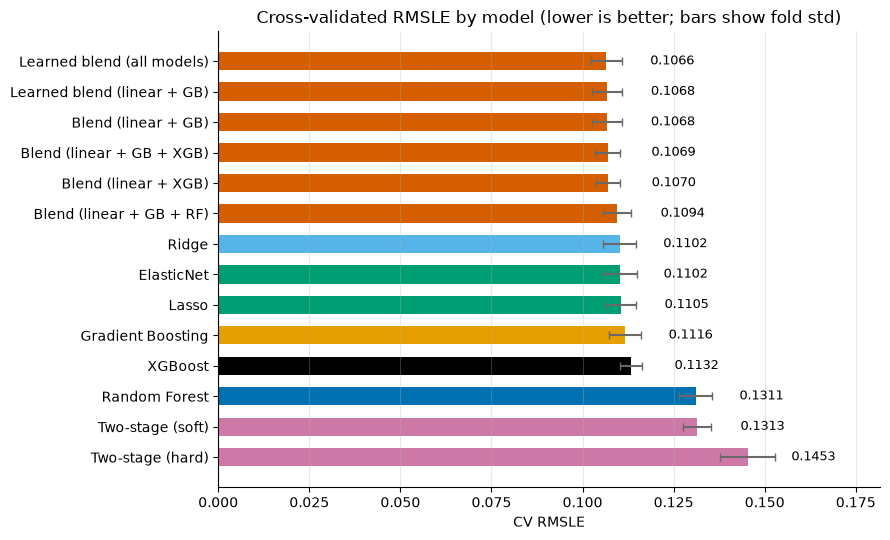

,CV RMSLE,Fold std,CV RMSE ($),vs. Random Forest
Model,,,,
Learned blend (all models),0.1066,0.0041,"$20,288",-18.7%
Blend (linear + GB),0.1068,0.0041,"$20,112",-18.5%
Learned blend (linear + GB),0.1068,0.0041,"$20,112",-18.5%
Blend (linear + GB + XGB),0.1069,0.0034,"$20,467",-18.4%
Blend (linear + XGB),0.1070,0.0032,"$20,628",-18.4%
Blend (linear + GB + RF),0.1094,0.0038,"$21,384",-16.5%
Ridge,0.1102,0.0045,"$20,749",-16.0%
ElasticNet,0.1102,0.0047,"$20,880",-15.9%
Lasso,0.1105,0.0042,"$20,967",-15.7%


In [21]:
cv_rows = []
for name, predictions in oof_predictions.items():
    mean_score, std_score = fold_rmsle(predictions)
    cv_rows.append({"Model": name, "CV RMSLE": mean_score, "Fold std": std_score,
                    "CV RMSE ($)": rmse_score(y_train, predictions)})

cv_comparison = pd.DataFrame(cv_rows).set_index("Model").sort_values("CV RMSLE")
cv_comparison["vs. Random Forest"] = cv_comparison["CV RMSLE"] / cv_comparison.loc["Random Forest", "CV RMSLE"] - 1


def family_color(name):
    return MODEL_COLORS.get(name, MODEL_COLORS["Blend"] if "blend" in name.lower() else "gray")


ordered = cv_comparison.sort_values("CV RMSLE", ascending=False)
fig, ax = plt.subplots(figsize=(9, 5.5))
ax.barh(ordered.index, ordered["CV RMSLE"], xerr=ordered["Fold std"],
        color=[family_color(n) for n in ordered.index], height=0.6,
        error_kw={"ecolor": "dimgray", "capsize": 3})
for y_pos, value in enumerate(ordered["CV RMSLE"]):
    ax.text(value + 0.012, y_pos, f"{value:.4f}", va="center", fontsize=9)
ax.set_xlim(0, ordered["CV RMSLE"].max() * 1.25)
ax.set_title("Cross-validated RMSLE by model (lower is better; bars show fold std)")
ax.set_xlabel("CV RMSLE")
ax.grid(axis="y", visible=False)
plt.tight_layout()
plt.show()

cv_comparison.style.format({"CV RMSLE": "{:.4f}", "Fold std": "{:.4f}", "CV RMSE ($)": "${:,.0f}",
                            "vs. Random Forest": "{:+.1%}"})

**What the results show.**

1. **Every regularised linear model and both boosting models beat the Random Forest by 14–16%** (CV RMSLE 0.110–0.113 against 0.131).
2. **Lasso, Ridge, and ElasticNet are tied** (0.1102–0.1105). Lasso reaches that accuracy using only **105 of 256 encoded features**; it sets the other 151 coefficients to exactly zero. The penalty selects features by itself.
3. **XGBoost does not beat scikit-learn's Gradient Boosting** (0.1132 against 0.1116). Both implement the same algorithm; on about 1,000 houses XGBoost's extras bring no gain.
4. **Splitting by price tier does not help.** With fixed tiers (below \$100k, \$100k to \$300k, \$300k and above), the soft version only ties the plain Random Forest (0.1313 against 0.1311) and the hard version is worse (0.1453). Out of fold, the classifier recognises only **56% of low-price and 65% of high-price houses** and sends the rest to the mid tier, so exactly the houses the split was meant to help are predicted by the wrong model. The low and high tier models also learn from only about 75 houses each per fold. (A separate check with Ridge + Gradient Boosting blends as the tier models gave 0.1099 soft and 0.1154 hard, against 0.1068 for the same blend without tiers.)
5. **Blends of a linear and a boosting model are best** (0.1066–0.1070, about 18.5% better than the Random Forest), and how they are weighted hardly matters:
   - Learned weights for Ridge + GB come out at **50% / 50% in every fold**, identical to equal weights.
   - Learned weights over all six models give about 20% to each linear model, 21% to Gradient Boosting, 18% to XGBoost, and **0–3% to the Random Forest**. The data drops the Random Forest on its own, just as Lasso drops unimportant features. Adding it with equal weight makes a blend worse (0.1094).

The differences among the top blends (0.1066–0.1070) are a tenth of the fold std, so they are ties. The large, reliable gap is between these blends and the Random Forest. **Choice rule:** among the candidates within 0.0002 of the lowest CV RMSLE (a tie at four decimals, about a twentieth of the fold std), the simplest is selected: the fewest member models, and fixed weights before learned ones. Three candidates tie (0.1066–0.1068): the learned blend of all models (five models with non-zero weight, plus learned weights), and Ridge + Gradient Boosting with equal or learned weights. **The selected model is the equal-weight blend of Ridge and Gradient Boosting** (`Blend (linear + GB)`). A blend of five models would cost more to train, maintain, and explain, for a gain the data cannot separate from noise.

## 10. Bias at the extremes

Grouping houses by their **actual** price makes every imperfect model look biased: a house that sold unusually cheaply often did so for reasons the features cannot see, so every model over-predicts it (*regression to the mean*).

The fair check groups houses by their **predicted** price. If a model is unbiased, then among the houses it predicts at, say, \$300k, the average error should be about zero. A trend in that view is real, systematic bias. Both views use out-of-fold predictions in ten equal-sized groups.

Within 0.0002 of the best CV RMSLE: ['Learned blend (all models)', 'Blend (linear + GB)', 'Learned blend (linear + GB)']
Selected (simplest of these): Blend (linear + GB)


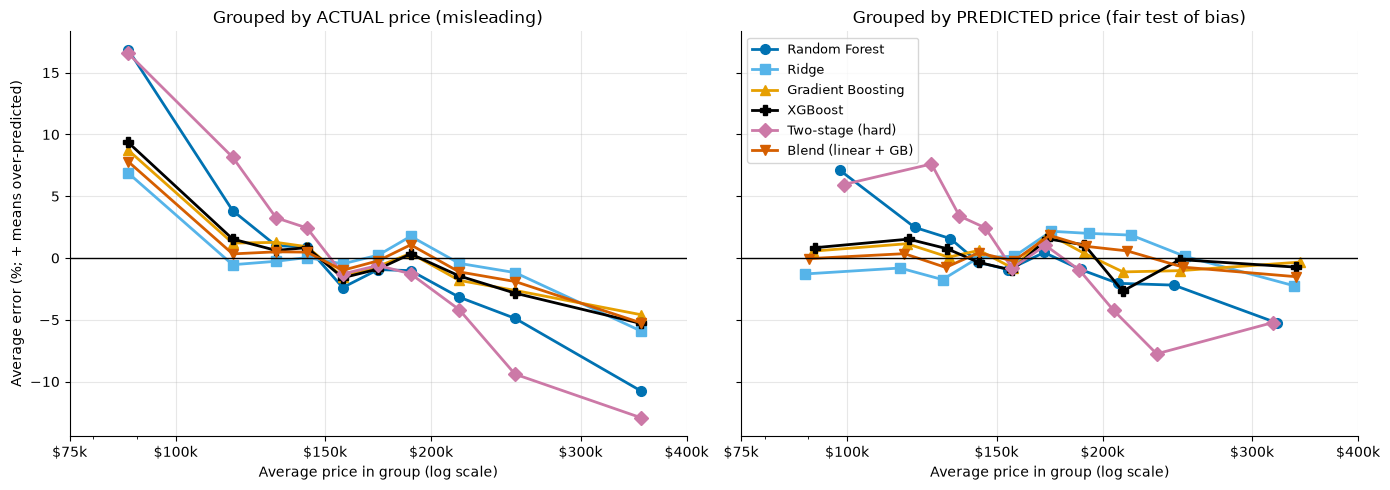

,Cheapest 10% (predicted),Most expensive 10% (predicted),Largest decile bias
Model,,,
Blend (linear + GB + XGB),+0.7%,-1.1%,+1.6%
Blend (linear + GB),-0.0%,-1.5%,+1.8%
Learned blend (linear + GB),-0.0%,-1.5%,+1.8%
Gradient Boosting,+0.6%,-0.3%,+2.0%
Blend (linear + XGB),+0.1%,-2.0%,+2.0%
Ridge,-1.3%,-2.2%,+2.2%
Learned blend (all models),-0.2%,-2.0%,+2.3%
ElasticNet,-1.7%,-1.7%,+2.4%
Lasso,-1.5%,-2.1%,+2.6%


In [22]:
TIE = 0.0002  # differences this small are a tie at four decimals


def complexity(name):
    """(number of member models, 1 if the weights are learned): smaller is simpler."""
    members = LEARNED_BLENDS.get(name) or BLENDS.get(name) or [name]
    return len(members), int(name in LEARNED_BLENDS)


near_best = cv_comparison.index[cv_comparison["CV RMSLE"] <= cv_comparison["CV RMSLE"].min() + TIE]
SELECTED = min(near_best, key=lambda n: (complexity(n), cv_comparison.loc[n, "CV RMSLE"]))
print("Within", TIE, "of the best CV RMSLE:", list(near_best))
print("Selected (simplest of these):", SELECTED)
BIAS_MODELS = ["Random Forest", BEST_LINEAR, "Gradient Boosting", "XGBoost", "Two-stage (hard)", SELECTED]
MARKERS = ["o", "s", "^", "P", "D", "v"]


def binned_bias(predictions, group_by, n_bins=10):
    """Mean log error (predicted − actual) and mean price per decile of `group_by`."""
    log_error = np.log1p(predictions) - np.log1p(y_train.to_numpy())
    frame = pd.DataFrame({"error": log_error, "price": group_by, "bin": pd.qcut(group_by, n_bins, labels=False)})
    return frame.groupby("bin").agg(price=("price", "mean"), error=("error", "mean"))


fig, axes = plt.subplots(1, 2, figsize=(14, 5), sharey=True)
views = [
    (axes[0], lambda p: y_train.to_numpy(), "Grouped by ACTUAL price (misleading)"),
    (axes[1], lambda p: p, "Grouped by PREDICTED price (fair test of bias)"),
]
for ax, grouping, title in views:
    for name, marker in zip(BIAS_MODELS, MARKERS):
        bias = binned_bias(oof_predictions[name], grouping(oof_predictions[name]))
        ax.plot(bias["price"], bias["error"] * 100, marker=marker, markersize=7,
                linewidth=2, color=family_color(name), label=name)
    ax.axhline(0, color="black", linewidth=1)
    ax.set_xscale("log")
    ax.set_xticks([75_000, 100_000, 150_000, 200_000, 300_000, 400_000])
    ax.xaxis.set_major_formatter(money)
    ax.xaxis.set_minor_formatter(plt.NullFormatter())
    ax.set_title(title)
    ax.set_xlabel("Average price in group (log scale)")
axes[0].set_ylabel("Average error (%; + means over-predicted)")
axes[1].legend(loc="upper left", fontsize=9)
plt.tight_layout()
plt.show()

bias_rows = []
for name in oof_predictions:
    bias = binned_bias(oof_predictions[name], oof_predictions[name])
    bias_rows.append({"Model": name, "Cheapest 10% (predicted)": bias["error"].iloc[0],
                      "Most expensive 10% (predicted)": bias["error"].iloc[-1],
                      "Largest decile bias": bias["error"].abs().max()})
pd.DataFrame(bias_rows).set_index("Model").sort_values("Largest decile bias").style.format("{:+.1%}")

**What the two views show.**

- **Left (grouped by actual price):** every model, the best included, appears to over-predict cheap houses and under-predict expensive ones. This is mostly regression to the mean, not a flaw of any one model.
- **Right (grouped by predicted price), the fair test:**
  - **The Random Forest has a real bias:** +7.1% in its cheapest decile and −5.3% in its most expensive. A forest's prediction is an average of training prices, so it is pulled towards the middle.
  - **Linear models, boosting models, and every blend without the Random Forest have no meaningful bias:** every decile stays within about ±2.7%.
  - **The two-stage model does not fix it.** The hard version keeps almost the same end bias as the plain forest (+5.9% / −5.2%); the soft version is worse (+8.7% / −7.2%), because averaging the tier models by probability pulls predictions back to the middle again.

**Conclusion:** the bias at the extremes is a property of the Random Forest. The fix is to change the model type, not to split the data into tiers.

## 11. Holdout check

Each candidate, fitted on all of `train_part`, now predicts `valid_part` for the first time. This score played no part in any decision, so it is an unbiased estimate for unseen houses.

In [23]:
holdout_predictions = {name: pipeline.predict(X_valid) for name, pipeline in fitted_pipelines.items()}
for name, members in BLENDS.items():
    holdout_predictions[name] = blend([holdout_predictions[m] for m in members])
for name, members in LEARNED_BLENDS.items():
    holdout_predictions[name] = blend([holdout_predictions[m] for m in members], learned_weights[name])

holdout_table = pd.DataFrame({
    "CV RMSLE": cv_comparison["CV RMSLE"],
    "Holdout RMSLE": {n: rmsle_score(y_valid, p) for n, p in holdout_predictions.items()},
    "Holdout RMSE ($)": {n: rmse_score(y_valid, p) for n, p in holdout_predictions.items()},
}).sort_values("CV RMSLE")
holdout_table["Holdout RMSE / mean price"] = holdout_table["Holdout RMSE ($)"] / y_valid.mean()
holdout_table.style.format({"CV RMSLE": "{:.4f}", "Holdout RMSLE": "{:.4f}", "Holdout RMSE ($)": "${:,.0f}",
                            "Holdout RMSE / mean price": "{:.1%}"})

,CV RMSLE,Holdout RMSLE,Holdout RMSE ($),Holdout RMSE / mean price
Learned blend (all models),0.1066,0.1250,"$22,840",12.8%
Blend (linear + GB),0.1068,0.1281,"$22,097",12.4%
Learned blend (linear + GB),0.1068,0.1281,"$22,097",12.4%
Blend (linear + GB + XGB),0.1069,0.1267,"$22,540",12.6%
Blend (linear + XGB),0.1070,0.1246,"$23,465",13.1%
Blend (linear + GB + RF),0.1094,0.1295,"$23,181",13.0%
Ridge,0.1102,0.1275,"$23,789",13.3%
ElasticNet,0.1102,0.1262,"$24,086",13.5%
Lasso,0.1105,0.1261,"$24,244",13.6%
Gradient Boosting,0.1116,0.1348,"$21,838",12.2%


**Reading the holdout.**

- **Every model scores worse on the holdout than in CV** (the selected blend: 0.1068 → 0.1281; the Random Forest: 0.1311 → 0.1451). The CV scores are slightly optimistic, and these 292 houses are harder for every model: they contain 6 houses from the commercial zone, against 4 in all of `train_part` (section 12).
- **The ranking holds where it matters.** Linear models and blends beat the Random Forest by 11–14% on the holdout too, and both two-stage versions are again the worst.
- **The top group is within about 0.004** (0.1246–0.1281), which 292 houses cannot reliably separate. The selected model scores 0.1281, at the upper end of that range. The learned blend of all models scores 0.1250, but a 0.003 difference on 292 houses is within noise.

The final model stays the one chosen by CV. Picking a different model because of its holdout score would turn the holdout into another tuning set.

## 12. Error analysis

### Predicted vs. actual prices for the selected model

Two sets of houses, neither seen by the model that predicted them: every house in `train_part` (out-of-fold) and the 292 holdout houses.

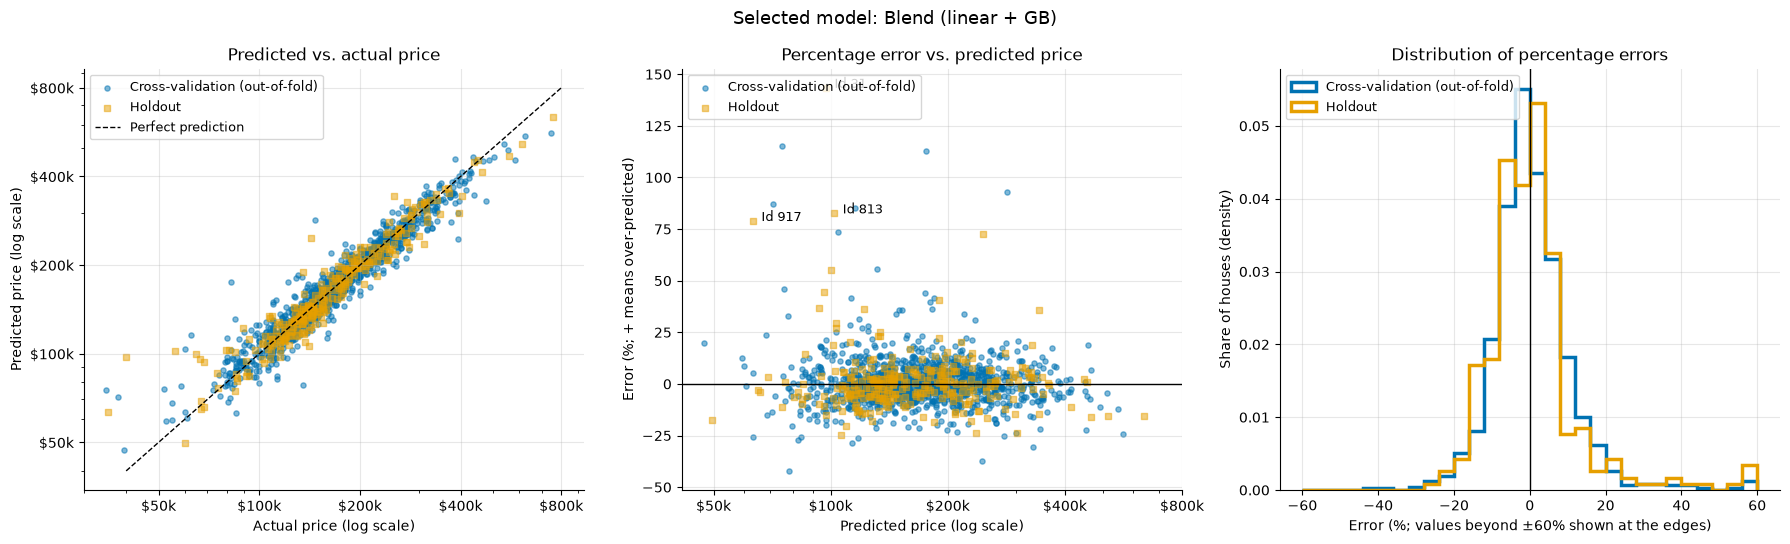

,Houses,Median error,Within ±5%,Within ±10%,Within ±20%,Over ±30%
Cross-validation (out-of-fold),"1,166",5.3%,47%,77%,95%,2.0%
Holdout,292,5.5%,46%,74%,92%,3.4%


In [24]:
error_sets = {
    "Cross-validation (out-of-fold)": (y_train.to_numpy(), oof_predictions[SELECTED], train_part["Id"].to_numpy(), MAIN_COLOR, "o"),
    "Holdout": (y_valid.to_numpy(), holdout_predictions[SELECTED], valid_part["Id"].to_numpy(), "#E69F00", "s"),
}

fig, axes = plt.subplots(1, 3, figsize=(18, 5.5))
price_ticks = [50_000, 100_000, 200_000, 400_000, 800_000]
for label, (actual, predicted, ids, color, marker) in error_sets.items():
    percent_error = (predicted / actual - 1) * 100
    axes[0].scatter(actual, predicted, s=14, alpha=0.5, color=color, marker=marker, label=label)
    axes[1].scatter(predicted, percent_error, s=14, alpha=0.5, color=color, marker=marker, label=label)
    axes[2].hist(np.clip(percent_error, -59.9, 59.9), bins=np.arange(-60, 62, 4), density=True,
                 histtype="step", linewidth=2.5, color=color, label=label)
    if label == "Holdout":
        for i in np.argsort(-np.abs(percent_error))[:3]:
            axes[1].annotate(f"Id {ids[i]}", (predicted[i], percent_error[i]),
                             xytext=(6, 0), textcoords="offset points", fontsize=9)

axes[0].plot([40_000, 800_000], [40_000, 800_000], color="black", linestyle="--", linewidth=1, label="Perfect prediction")
axes[0].set_title("Predicted vs. actual price")
axes[0].set_xlabel("Actual price (log scale)")
axes[0].set_ylabel("Predicted price (log scale)")
axes[0].set_yscale("log")
axes[0].set_yticks(price_ticks)
axes[0].yaxis.set_major_formatter(money)
axes[0].yaxis.set_minor_formatter(plt.NullFormatter())
axes[1].axhline(0, color="black", linewidth=1)
axes[1].set_title("Percentage error vs. predicted price")
axes[1].set_xlabel("Predicted price (log scale)")
axes[1].set_ylabel("Error (%; + means over-predicted)")
for ax in axes[:2]:
    ax.set_xscale("log")
    ax.set_xticks(price_ticks)
    ax.xaxis.set_major_formatter(money)
    ax.xaxis.set_minor_formatter(plt.NullFormatter())
axes[2].axvline(0, color="black", linewidth=1)
axes[2].set_title("Distribution of percentage errors")
axes[2].set_xlabel("Error (%; values beyond ±60% shown at the edges)")
axes[2].set_ylabel("Share of houses (density)")
for ax in axes:
    ax.legend(fontsize=9, loc="upper left")
fig.suptitle(f"Selected model: {SELECTED}", fontsize=13)
plt.tight_layout()
plt.show()

summary_rows = {}
for label, (actual, predicted, *_rest) in error_sets.items():
    absolute_error = np.abs(predicted / actual - 1)
    summary_rows[label] = {"Houses": len(actual), "Median error": np.median(absolute_error),
                           "Within ±5%": np.mean(absolute_error <= 0.05), "Within ±10%": np.mean(absolute_error <= 0.10),
                           "Within ±20%": np.mean(absolute_error <= 0.20), "Over ±30%": np.mean(absolute_error > 0.30)}
(pd.DataFrame(summary_rows).T
 .style.format({"Houses": "{:,.0f}", "Median error": "{:.1%}", "Within ±5%": "{:.0%}", "Within ±10%": "{:.0%}",
                "Within ±20%": "{:.0%}", "Over ±30%": "{:.1%}"}))

### Houses with large errors

The median error is only about 5%, yet RMSLE is about 11–13%. RMSLE squares each error before averaging, so a few large misses weigh far more than many small ones: a 50% error counts about 64 times as much as a 5% error. The next cells isolate the houses whose prediction is off by **more than 30%**.

In [25]:
LARGE_ERROR = 0.30
DETAIL_COLS = ["Id", "Neighborhood", "MSZoning", "SaleType", "SaleCondition",
               "OverallQual", "OverallCond", "GrLivArea", "TotalBsmtSF", "YearBuilt"]

error_frames = []
for label, actual, predicted, source in [
    ("Cross-validation", y_train, oof_predictions[SELECTED], train_part),
    ("Holdout", y_valid, holdout_predictions[SELECTED], valid_part),
]:
    frame = source[DETAIL_COLS].copy()
    frame.insert(0, "Set", label)
    frame["Actual"] = actual.to_numpy()
    frame["Predicted"] = predicted
    frame["Error (%)"] = (predicted / actual.to_numpy() - 1) * 100
    frame["Log error"] = np.log1p(predicted) - np.log1p(actual.to_numpy())
    error_frames.append(frame)

house_errors = pd.concat(error_frames, ignore_index=True)
house_errors["Squared log error"] = house_errors["Log error"] ** 2
house_errors["Large error"] = house_errors["Error (%)"].abs() > LARGE_ERROR * 100

impact_rows = {}
for label, group in house_errors.groupby("Set", sort=False):
    large = group["Large error"]
    impact_rows[label] = {
        "Houses": len(group),
        "Large-error houses": int(large.sum()),
        "Share of houses": large.mean(),
        "Share of total squared error": group.loc[large, "Squared log error"].sum() / group["Squared log error"].sum(),
        "RMSLE (all houses)": np.sqrt(group["Squared log error"].mean()),
        "RMSLE without large errors": np.sqrt(group.loc[~large, "Squared log error"].mean()),
    }
display(pd.DataFrame(impact_rows).T.style.format({
    "Houses": "{:,.0f}", "Large-error houses": "{:,.0f}", "Share of houses": "{:.1%}",
    "Share of total squared error": "{:.0%}", "RMSLE (all houses)": "{:.4f}", "RMSLE without large errors": "{:.4f}",
}))

large_errors = (house_errors.loc[house_errors["Large error"]]
                .sort_values("Error (%)", key=np.abs, ascending=False)
                .drop(columns=["Large error", "Log error", "Squared log error"]))
print(f"{len(large_errors)} houses off by more than {LARGE_ERROR:.0%}: "
      f"{(large_errors['Error (%)'] > 0).sum()} over-predicted, {(large_errors['Error (%)'] < 0).sum()} under-predicted")
(large_errors.style
 .format({"Actual": "${:,.0f}", "Predicted": "${:,.0f}", "Error (%)": "{:+.0f}%", "GrLivArea": "{:,.0f}", "TotalBsmtSF": "{:,.0f}"})
 .hide(axis="index"))

,Houses,Large-error houses,Share of houses,Share of total squared error,RMSLE (all houses),RMSLE without large errors
Cross-validation,"1,166",23,2.0%,36%,0.1068,0.0862
Holdout,292,10,3.4%,53%,0.1281,0.0897


33 houses off by more than 30%: 30 over-predicted, 3 under-predicted


Set,Id,Neighborhood,MSZoning,SaleType,SaleCondition,OverallQual,OverallCond,GrLivArea,TotalBsmtSF,YearBuilt,Actual,Predicted,Error (%)
Holdout,31,IDOTRR,C (all),WD,Normal,4,4,"1,317",649,1920,"$40,000","$97,367",+143%
Cross-validation,496,IDOTRR,C (all),WD,Abnorml,4,5,720,720,1920,"$34,900","$75,041",+115%
Cross-validation,633,NWAmes,RL,WD,Family,7,5,"1,411","1,386",1977,"$82,500","$175,427",+113%
Cross-validation,1325,Somerst,RL,New,Partial,8,5,"1,795","1,795",2006,"$147,000","$283,897",+93%
Cross-validation,969,OldTown,RM,WD,Abnorml,3,6,968,600,1910,"$37,900","$71,020",+87%
Cross-validation,463,Sawyer,RL,WD,Normal,5,5,864,864,1965,"$62,383","$115,465",+85%
Holdout,813,IDOTRR,C (all),WD,Alloca,5,5,"1,044",540,1952,"$55,993","$102,236",+83%
Holdout,917,IDOTRR,C (all),WD,Abnorml,2,3,480,480,1949,"$35,311","$63,174",+79%
Cross-validation,411,Edwards,RL,COD,Abnorml,5,3,"1,276","1,276",1958,"$60,000","$104,147",+74%
Holdout,589,ClearCr,RL,WD,Partial,5,8,"1,473","1,437",1968,"$143,000","$246,778",+73%


"RMSLE without large errors" is **not** a score the model can reach: unseen houses cannot be removed before predicting them. It shows how much of the error comes from a few houses.

Most large errors are over-predictions of cheap houses, and the same names keep appearing: `Abnorml` sales, `IDOTRR` and `OldTown`, the commercial zone `C (all)`.

### Special cases: bias or noise?

Whether these errors can be fixed depends on how the **whole group** is predicted, not only its worst members:

| Pattern across every house in the group | Meaning | Possible fix |
|---|---|---|
| Errors lean to one side (mean error far from 0) | **Bias:** the model under-uses something it could learn | Features, or less shrinkage for that group |
| Errors centred on 0 but widely spread | **Noise:** price depends on things the features do not record | Nothing for those houses; at most stop them from distorting the fit for others |
| Very few houses in the group | **Too little data** to learn or to test a correction | None with this data |

The table uses cross-validation predictions only and shows, for each group with at least 5 houses: the **mean error** (+5% = over-predicted by about 5% on average), **t** (mean error divided by its standard error; beyond about ±2 the lean is unlikely to be chance), the **error spread** (standard deviation of log errors), and the group's **share of the squared error**.

In [26]:
cv_errors = house_errors.loc[house_errors["Set"] == "Cross-validation"]


def group_bias(column, min_houses=5):
    """Mean, spread, and error share of the signed log error for each category."""
    table = cv_errors.groupby(column).agg(
        houses=("Log error", "size"), mean_error=("Log error", "mean"),
        spread=("Log error", "std"), squared_error=("Squared log error", "sum"),
    )
    table["t"] = table["mean_error"] / (table["spread"] / np.sqrt(table["houses"]))
    table["share"] = table["squared_error"] / cv_errors["Squared log error"].sum()
    table = table.loc[table["houses"] >= min_houses].drop(columns="squared_error")
    table.columns = ["Houses", "Mean error", "Error spread", "t", "Share of squared error"]
    return table.sort_values("Share of squared error", ascending=False)


for column in ["SaleCondition", "MSZoning", "Neighborhood"]:
    print(column)
    display(group_bias(column).head(8).style.format({
        "Mean error": "{:+.1%}", "Error spread": "{:.3f}", "t": "{:+.1f}", "Share of squared error": "{:.0%}",
    }))

SaleCondition


,Houses,Mean error,Error spread,t,Share of squared error
SaleCondition,,,,,
Normal,964,+0.1%,0.089,+0.3,57%
Abnorml,77,+1.5%,0.206,+0.7,24%
Partial,96,-0.6%,0.129,-0.4,12%
Family,18,+2.1%,0.211,+0.4,6%
Alloca,7,-10.8%,0.102,-2.8,1%


MSZoning


,Houses,Mean error,Error spread,t,Share of squared error
MSZoning,,,,,
RL,922,+0.0%,0.103,+0.1,73%
RM,172,+0.3%,0.111,+0.4,16%
FV,53,-1.2%,0.085,-1.0,3%
RH,15,-1.6%,0.138,-0.4,2%


Neighborhood


,Houses,Mean error,Error spread,t,Share of squared error
Neighborhood,,,,,
OldTown,91,+0.2%,0.141,+0.1,13%
NAmes,181,+0.6%,0.098,+0.8,13%
Edwards,85,+1.0%,0.129,+0.7,11%
Sawyer,58,+1.2%,0.131,+0.7,7%
Somerst,69,-0.5%,0.113,-0.4,7%
NWAmes,66,+1.0%,0.115,+0.7,7%
IDOTRR,26,+2.0%,0.185,+0.6,7%
BrkSide,45,-1.3%,0.119,-0.7,5%


**What the group tables show.**

- **Unusual sales are noise, not bias.** `Abnorml` sales (foreclosures, short sales) are over-predicted by only about 1.5% on average, yet their error spread is 0.206, more than twice that of normal sales (0.089). Together with `Family`, `Alloca`, and `AdjLand` they are 9% of the houses but cause about a third of the squared error. The data does not record that a seller was in distress, so these errors cannot be predicted away.
- **No zoning or neighborhood has a large, reliable lean.** Every listed group is within about ±2% with |t| < 1. `Alloca` leans −11% (t = −2.8), but it has only 7 houses and 1% of the error.
- **The commercial zone `C (all)` does not appear,** because `train_part` has only 4 such houses.

### The commercial zone `C (all)`

In [27]:
UNUSUAL_SALES = ["Abnorml", "Family", "Alloca", "AdjLand"]
SPECIAL_GROUPS = {
    "Commercial zone (MSZoning = C (all))": lambda d: d["MSZoning"].eq("C (all)"),
    "Unusual sale (Abnorml, Family, Alloca, AdjLand)": lambda d: d["SaleCondition"].isin(UNUSUAL_SALES),
    "Partial sale (new, unfinished house)": lambda d: d["SaleCondition"].eq("Partial"),
}
display(pd.DataFrame({
    name: {"train_part": int(is_member(train_part).sum()),
           "valid_part (holdout)": int(is_member(valid_part).sum()),
           "test.csv": int(is_member(test_clean).sum())}
    for name, is_member in SPECIAL_GROUPS.items()
}).T)

(house_errors.loc[house_errors["MSZoning"].eq("C (all)"),
                  ["Set", "Id", "Neighborhood", "SaleCondition", "OverallQual", "GrLivArea", "Actual", "Predicted", "Error (%)"]]
 .sort_values("Error (%)", ascending=False)
 .style.format({"Actual": "${:,.0f}", "Predicted": "${:,.0f}", "Error (%)": "{:+.0f}%", "GrLivArea": "{:,.0f}"})
 .hide(axis="index"))

,train_part,valid_part (holdout),test.csv
Commercial zone (MSZoning = C (all)),4,6,15
"Unusual sale (Abnorml, Family, Alloca, AdjLand)",106,31,135
"Partial sale (new, unfinished house)",96,27,120


Set,Id,Neighborhood,SaleCondition,OverallQual,GrLivArea,Actual,Predicted,Error (%)
Holdout,31,IDOTRR,Normal,4,"1,317","$40,000","$97,367",+143%
Cross-validation,496,IDOTRR,Abnorml,4,720,"$34,900","$75,041",+115%
Holdout,813,IDOTRR,Alloca,5,"1,044","$55,993","$102,236",+83%
Holdout,917,IDOTRR,Abnorml,2,480,"$35,311","$63,174",+79%
Holdout,1280,IDOTRR,Abnorml,4,"1,128","$68,400","$93,521",+37%
Cross-validation,94,OldTown,Normal,6,"2,291","$133,900","$182,620",+36%
Holdout,1062,IDOTRR,Normal,3,894,"$81,000","$103,010",+27%
Cross-validation,558,IDOTRR,Normal,4,"1,336","$108,000","$122,736",+14%
Holdout,712,IDOTRR,Abnorml,4,"1,178","$102,776","$108,496",+6%
Cross-validation,89,IDOTRR,Abnorml,3,"1,526","$85,000","$63,115",-26%


**Reading the commercial-zone table.**

- `train_part` has only **4** commercial-zone houses, and even they do not agree on a direction: their errors range from −25% to +111%. The model has almost nothing to learn from.
- The holdout has **6**, and 4 of them are among the holdout's 10 large errors. This alone explains much of why the holdout scores worse than cross-validation.
- `test.csv` has **15**. The final model is refitted on all labelled houses and sees all 10, which helps a little, but 10 houses are still too few for a reliable correction.

No correction is tuned for this group: with 4 training houses, any correction chosen by cross-validation would be chosen by chance.

**Overall:** the large errors are mostly sales whose price depends on circumstances the data does not record, and a zone with too few examples to learn. Neither is a model flaw that more tuning or new features can fix. (A separate check of engineered features, such as total area, house age, total bathrooms, and quality × area, changed the blend's CV RMSLE by at most 0.0007, so none were added.)

### Expensive houses: why the top is under-predicted

The predicted-vs-actual plot above suggests that houses above about \$300k are under-predicted. Section 10 showed that most of such a pattern is regression to the mean, but not whether *all* of it is. Two checks separate the two parts:

1. **Choose the expensive houses two ways.** Chosen by actual price, the group contains houses that sold above what their features justify, so any model under-predicts it. Chosen by predicted price, that selection effect disappears; a lean that remains is evidence of real bias.
2. **Group by features.** Quality and area are known before predicting, so a lean within a quality grade or size band is real bias, not a selection effect.

In [28]:
log_actual = np.log1p(y_train.to_numpy())
log_selected = np.log1p(oof_predictions[SELECTED])
total_area = (train_part["TotalBsmtSF"] + train_part["1stFlrSF"] + train_part["2ndFlrSF"]).to_numpy()
top_frame = pd.DataFrame({
    "Log error": log_selected - log_actual,
    "OverallQual": train_part["OverallQual"].to_numpy(),
    "Total area (sq ft)": pd.cut(total_area, [0, 1500, 2500, 3000, 3500, 4000, np.inf],
                                 labels=["< 1,500", "1,500–2,500", "2,500–3,000", "3,000–3,500", "3,500–4,000", "> 4,000"]),
})


LEAN_FORMAT = {"Houses": "{:,.0f}", "Mean error": "{:+.1%}", "95% CI low": "{:+.1%}",
               "95% CI high": "{:+.1%}", "t": "{:+.1f}"}


def lean(errors):
    """Mean log error, its 95% confidence interval (normal approximation), and t."""
    standard_error = errors.std() / np.sqrt(len(errors))
    return {"Houses": len(errors), "Mean error": errors.mean(),
            "95% CI low": errors.mean() - 1.96 * standard_error,
            "95% CI high": errors.mean() + 1.96 * standard_error,
            "t": errors.mean() / standard_error}


print("Expensive houses chosen two ways")
display(pd.DataFrame({
    "Actual price ≥ $300k": lean(top_frame.loc[y_train.to_numpy() >= 300_000, "Log error"]),
    "Predicted price ≥ $300k": lean(top_frame.loc[oof_predictions[SELECTED] >= 300_000, "Log error"]),
}).T.style.format(LEAN_FORMAT))
print(f"Slope of log actual on log predicted: {np.polyfit(log_selected, log_actual, 1)[0]:.3f}  (1 = predictions not compressed)")

for column in ["OverallQual", "Total area (sq ft)"]:
    print(column)
    table = pd.DataFrame({value: lean(group["Log error"])
                          for value, group in top_frame.groupby(column, observed=True) if len(group) >= 5}).T
    display(table.style.format(LEAN_FORMAT))

Expensive houses chosen two ways


,Houses,Mean error,95% CI low,95% CI high,t
Actual price ≥ $300k,91,-6.0%,-8.2%,-3.7%,-5.2
Predicted price ≥ $300k,85,-2.2%,-4.4%,-0.0%,-2.0


Slope of log actual on log predicted: 1.011  (1 = predictions not compressed)
OverallQual


,Houses,Mean error,95% CI low,95% CI high,t
3,16,+4.0%,-6.9%,+14.9%,+0.7
4,88,-1.0%,-4.2%,+2.3%,-0.6
5,308,+0.0%,-1.2%,+1.2%,+0.1
6,311,+0.6%,-0.4%,+1.6%,+1.2
7,258,+0.5%,-0.6%,+1.7%,+0.9
8,135,-0.2%,-2.0%,+1.7%,-0.2
9,36,-3.9%,-6.7%,-1.1%,-2.7
10,11,-7.1%,-16.6%,+2.4%,-1.5


Total area (sq ft)


,Houses,Mean error,95% CI low,95% CI high,t
"< 1,500",49,+2.5%,-2.0%,+7.0%,+1.1
"1,500–2,500",538,-0.1%,-1.0%,+0.7%,-0.3
"2,500–3,000",283,+0.9%,-0.4%,+2.1%,+1.4
"3,000–3,500",171,+0.4%,-1.0%,+1.7%,+0.5
"3,500–4,000",77,-0.9%,-3.5%,+1.8%,-0.6
"> 4,000",48,-4.1%,-7.8%,-0.5%,-2.2


**What the checks show.** Errors are mean log errors (predicted − actual), so −2% means under-predicted by about 2%.

- **Most of the apparent under-prediction is regression to the mean.** Chosen by actual price, houses above \$300k are under-predicted by 6.0%; chosen by predicted price, by 2.2% (95% CI about −4.4% to 0%). The second figure is the fair measure of bias for houses the model prices above \$300k. The two groups contain different houses and the −2.2% is uncertain, so the 6.0% cannot be split precisely into a selection effect and real bias. The slope of log actual on log predicted price is 1.01, so the predictions as a whole are not compressed towards the middle.
- **A smaller lean remains at the very top.** Quality grades 4 to 8 and size bands from 1,500 to 4,000 sq ft all stay within ±1%; the two smallest groups at the bottom lean the other way (quality 3: +4.0%, 16 houses; under 1,500 sq ft: +2.5%, 49 houses), with |t| ≤ 1.1. Only the top leans clearly negative: quality 9 at −3.9% (t = −2.7, 36 houses), quality 10 at −7.1% (t = −1.5, 11 houses), and total floor area (including basement) above 4,000 sq ft at −4.1% (t = −2.2, 48 houses).
- **How much weight this evidence can bear.** Fourteen groups are tested here, so one |t| near 2 could arise by chance. What makes the lean credible is that the three top groups all point the same way, and that the calibration test below learns an upward shift for the top quality grades in every fold.

**Likely reasons (not tested separately).** Prices may rise faster at the top than in the middle: Ridge fits one slope per feature on the log scale, so a steeper top end would be under-predicted. And the top is thin: `train_part` has only 47 houses of quality 9–10, too few for Gradient Boosting to learn a separate pattern, while Ridge's penalty limits how far a few houses can move the fit. (A separate check that also encoded `OverallQual` as a category, so each grade gets its own price level, reduced the quality-9 lean from −3.9% to −2.1% but left quality 10 at −5.2% and the CV RMSLE unchanged, so it was not added.)

### Can a simple correction remove the top-end bias?

The lightest fix is **post-hoc calibration**: learn by how much a group is under-predicted on average, and raise its predictions by that amount. A separate model for expensive houses would have to learn from fewer than 100 houses, and the two-stage model (section 8) showed how routing houses to such a model goes wrong.

The rule may use only what is known before the price: the model's own prediction, or the house's features. The test is honest: for each fold, the shift is learned from the out-of-fold errors of the **other four folds** and applied to the held-out fold, the same way the learned blend weights are chosen.

In [29]:
CALIBRATION_RULES = {
    "Predicted ≥ $250k": oof_predictions[SELECTED] >= 250_000,
    "Predicted ≥ $300k": oof_predictions[SELECTED] >= 300_000,
    "Predicted ≥ $350k": oof_predictions[SELECTED] >= 350_000,
    "OverallQual ≥ 9": train_part["OverallQual"].to_numpy() >= 9,
}


def fold_scores(log_predictions):
    return np.array([np.sqrt(np.mean((log_predictions[held] - log_actual[held]) ** 2)) for _, held in cv_folds])


base_scores = fold_scores(log_selected)
calibration_rows = {"No calibration": {"CV RMSLE": base_scores.mean()}}
for name, in_group in CALIBRATION_RULES.items():
    calibrated, shifts = log_selected.copy(), []
    for fit_rows, held_rows in cv_folds:
        fit_group = fit_rows[in_group[fit_rows]]
        shift = np.mean(log_actual[fit_group] - log_selected[fit_group])  # learned on the other four folds
        calibrated[held_rows[in_group[held_rows]]] += shift
        shifts.append(np.expm1(shift))
    scores = fold_scores(calibrated)
    before, after = (log_selected - log_actual)[in_group], (calibrated - log_actual)[in_group]
    calibration_rows[name] = {
        "Houses": int(in_group.sum()),
        "Shift learned per fold": f"{min(shifts):+.1%} to {max(shifts):+.1%}",
        "Group mean error": f"{before.mean():+.1%} → {after.mean():+.1%}",
        "Group RMSLE": f"{np.sqrt(np.mean(before ** 2)):.4f} → {np.sqrt(np.mean(after ** 2)):.4f}",
        "CV RMSLE": scores.mean(),
        "Folds better": f"{np.sum(scores < base_scores)}/5",
    }

(pd.DataFrame(calibration_rows).T.fillna("")
 .style.format({"Houses": lambda v: f"{v:,.0f}" if v != "" else "", "CV RMSLE": "{:.4f}"}))

,CV RMSLE,Houses,Shift learned per fold,Group mean error,Group RMSLE,Folds better
No calibration,0.1068,,,,,
Predicted ≥ $250k,0.1067,171,+0.9% to +2.2%,-1.4% → +0.1%,0.1105 → 0.1103,3/5
Predicted ≥ $300k,0.1068,85,+1.1% to +3.2%,-2.2% → +0.0%,0.1050 → 0.1052,2/5
Predicted ≥ $350k,0.1068,36,+1.4% to +4.4%,-2.8% → +0.3%,0.0983 → 0.1001,3/5
OverallQual ≥ 9,0.1065,47,+3.6% to +6.8%,-4.7% → +0.3%,0.1155 → 0.1101,3/5


**Result.**

- **Calibrating by predicted price does nothing.** The group's mean error goes to zero, but its RMSLE does not fall, and at \$350k it rises (0.0983 → 0.1001). The lean is only about 2%, against a spread of about 10% for single houses, so removing it barely changes the squared error, and the shift learned per fold (between about 1% and 4%) adds noise of its own.
- **Calibrating by `OverallQual ≥ 9` corrects a real bias.** Every fold learns an upward shift of 3.6–6.8%, the group's mean error goes from −4.7% to +0.3%, and the group RMSLE falls by about 5% (0.1155 → 0.1101).
- **But the overall CV RMSLE improves only from 0.1068 to 0.1065, in 3 of 5 folds.** The gain is just above the 0.0002 tie margin, but it is not consistent: section 13 adopts a change only when it improves every fold, and this one improves only three. So **no calibration is added to the final model**.

**In practice,** where errors on expensive houses matter more (for example when losses are counted in dollars: 7% of a \$700k house is about \$50k), a correction for the top quality grades is a reasonable, transparent fix. Its shift should be learned again on the final model and checked again once more top-end sales are recorded. The other common answers to a thin top segment are a wider error range for such houses, or sending them to a human appraiser. A separate model for expensive houses is worth considering only with thousands of such sales and features that matter mainly at the top (views, architecture, custom finishes), none of which this data has.


**Summary.** Chosen by actual sale price, houses above \$300k have a mean log error of −6.0%; chosen by predicted price, −2.2% (95% CI about −4.4% to 0%). Most of the apparent under-prediction is therefore regression to the mean, a selection effect of grouping by the observed price, not model bias. Because the two groups contain different houses and the −2.2% is uncertain, the split cannot be stated precisely.

Grouping by features, which are known before predicting, still shows a lean at the very top: quality 9–10 (47 houses) and total floor area (including basement) above 4,000 sq ft (48 houses). Calibrating by `OverallQual ≥ 9` learns an upward shift in every fold (+3.6% to +6.8%) and lowers that group's RMSLE by about 5%. This is evidence of a mild, real under-prediction of the best houses, though with fewer than 50 houses per group its size is uncertain. Calibrating by predicted price has no effect.

**Decision:** no calibration is added. It improves the overall CV RMSLE by only 0.0003, in three of five folds, and rests on fewer than 50 houses.

## 13. Giving unusual sales less weight in training

Unusual sales cannot be predicted well, but they may still **pull the model** while it learns: a \$35k foreclosure of an otherwise ordinary house teaches the model that such houses are cheap, which shifts predictions for normal sales of similar houses.

The test: train every member of the selected model with a lower **sample weight** for unusual sales (1 = normal weight, 0 = no influence on the fit), and score on **every** house in each held-out fold, including the unusual ones. Unseen houses cannot be filtered out before predicting them, so the score must include them. For a learned blend, the blend weights are learned again (honestly, fold by fold) for each setting.

**Choice rule:** among the settings within 0.0002 of the lowest CV RMSLE (a tie at four decimals), the one closest to normal weight is used, because it changes the training the least. The per-fold differences show whether the gain is consistent or a lucky average.

In [30]:
if SELECTED in LEARNED_BLENDS:
    final_members = [m for m, w in zip(LEARNED_BLENDS[SELECTED], learned_weights[SELECTED]) if w > 0]
else:
    final_members = BLENDS.get(SELECTED, [SELECTED])
print("Members of the selected model:", final_members)

PARALLEL_JOBS = {"XGBoost": 4, "Lasso": 5, "Ridge": 5, "ElasticNet": 5, "Gradient Boosting": 5}
is_unusual = train_part["SaleCondition"].isin(UNUSUAL_SALES).to_numpy()


def combine(member_predictions):
    """Combine members the same way the selected model does: returns (oof blend, final weights)."""
    if len(member_predictions) == 1:
        return member_predictions[0], np.ones(1)
    if SELECTED in LEARNED_BLENDS:
        blended, _, weights = learned_blend(member_predictions)
        return blended, weights
    return blend(member_predictions), np.ones(len(member_predictions))


def per_fold_rmsle(predictions):
    return np.array([rmsle_score(y_train.iloc[held], predictions[held]) for _, held in cv_folds])


weight_rows, weight_results = [], {}
for unusual_weight in [1.0, 0.5, 0.25, 0.0]:
    sample_weight = np.where(is_unusual, unusual_weight, 1.0)
    member_oof = [
        oof_predictions[m] if unusual_weight == 1.0
        else oof_predict(best_pipelines[m], n_jobs=PARALLEL_JOBS.get(m, 1), sample_weight=sample_weight)
        for m in final_members
    ]
    blended, weights = combine(member_oof)
    weight_results[unusual_weight] = (blended, weights)
    squared_error = (np.log1p(blended) - np.log1p(y_train.to_numpy())) ** 2
    weight_rows.append({
        "Weight of unusual sales": unusual_weight,
        "CV RMSLE": fold_rmsle(blended)[0],
        "Folds better than weight 1": int(np.sum(per_fold_rmsle(blended) < per_fold_rmsle(weight_results[1.0][0]))),
        "RMSLE: normal and partial sales": np.sqrt(squared_error[~is_unusual].mean()),
        "RMSLE: unusual sales": np.sqrt(squared_error[is_unusual].mean()),
    })

weight_table = pd.DataFrame(weight_rows).set_index("Weight of unusual sales")
# Among near-ties with the best score, prefer the weight closest to 1 (the smallest change)
near_best = weight_table["CV RMSLE"] <= weight_table["CV RMSLE"].min() + 0.0002
UNUSUAL_WEIGHT = weight_table.index[near_best].max()
final_weights = weight_results[UNUSUAL_WEIGHT][1]
print("Selected weight for unusual sales:", UNUSUAL_WEIGHT)
print("Per-fold change vs. weight 1:",
      np.round(per_fold_rmsle(weight_results[UNUSUAL_WEIGHT][0]) - per_fold_rmsle(weight_results[1.0][0]), 4))
weight_table.style.format({"CV RMSLE": "{:.4f}", "RMSLE: normal and partial sales": "{:.4f}", "RMSLE: unusual sales": "{:.4f}"})

Members of the selected model: ['Ridge', 'Gradient Boosting']


Selected weight for unusual sales: 0.5
Per-fold change vs. weight 1: [-0.0012 -0.0014 -0.0014 -0.0018 -0.0009]


,CV RMSLE,Folds better than weight 1,RMSLE: normal and partial sales,RMSLE: unusual sales
Weight of unusual sales,,,,
1.000000,0.1068,0,0.0928,0.1987
0.500000,0.1054,5,0.0917,0.1959
0.250000,0.1059,5,0.0920,0.1972
0.000000,0.1073,1,0.0931,0.2005


**Result.**

- **Half weight (0.5) improves the CV RMSLE in all five folds** (0.1068 → 0.1054, by 0.0009–0.0018 per fold). Weight 0.25 is also better in all five folds but less so (0.1059); 0.5 has the lowest score.
- **It helps both groups,** including the unusual sales themselves: training is no longer pulled towards their noisy prices.
- **Zero weight is worse than doing nothing** (0.1073). Their prices are noisy but not useless, so the right move is to trust them less, not to ignore them.
- **The gain is small:** 0.0014, about a third of the fold std. It is adopted because it points the same way in every fold, not because of its size.


## 14. Final model

The final model is the selected candidate, with unusual sales weighted as chosen above, wrapped in one object so it can be fitted, scored, and inspected like any scikit-learn model.

### Holdout check of the final configuration

Fitted on `train_part` and scored once on the holdout. This only confirms the choice; it does not make it.

In [31]:
class BlendRegressor(BaseEstimator, RegressorMixin):
    """Weighted average of several pipelines' log-price predictions."""

    def __init__(self, members, weights):
        self.members = members  # list of (name, unfitted pipeline)
        self.weights = weights

    def fit(self, X, y, sample_weight=None):
        params = {} if sample_weight is None else {"model__sample_weight": sample_weight}
        self.fitted_ = [clone(pipeline).fit(X, y, **params) for _, pipeline in self.members]
        return self

    def predict(self, X):
        return blend([model.predict(X) for model in self.fitted_], self.weights)


def unusual_sale_weights(df):
    return np.where(df["SaleCondition"].isin(UNUSUAL_SALES), UNUSUAL_WEIGHT, 1.0)


final_model_spec = BlendRegressor([(m, best_pipelines[m]) for m in final_members], final_weights)
holdout_model = clone(final_model_spec).fit(X_train, y_train, sample_weight=unusual_sale_weights(train_part))

final_check = pd.DataFrame({
    "CV RMSLE": [cv_comparison.loc[SELECTED, "CV RMSLE"], weight_table.loc[UNUSUAL_WEIGHT, "CV RMSLE"]],
    "Holdout RMSLE": [rmsle_score(y_valid, holdout_predictions[SELECTED]),
                      rmsle_score(y_valid, holdout_model.predict(X_valid))],
}, index=[f"{SELECTED}", f"{SELECTED}, unusual sales weight {UNUSUAL_WEIGHT}"])
print("Members and weights:", {m: f"{w:.0%}" for m, w in zip(final_members, final_weights / final_weights.sum())})
final_check.style.format("{:.4f}")

Members and weights: {'Ridge': '50%', 'Gradient Boosting': '50%'}


,CV RMSLE,Holdout RMSLE
Blend (linear + GB),0.1068,0.1281
"Blend (linear + GB), unusual sales weight 0.5",0.1054,0.1273


**Reading the check.** Half weight for unusual sales improves the CV RMSLE (0.1068 → 0.1054, in all five folds) and the holdout points the same way (0.1281 → 0.1273). A difference of 0.0008 on 292 houses is far below what they can resolve (the top models already spread over 0.004), so the holdout is consistent with the gain but cannot confirm it on its own. The decision stays with cross-validation, as planned.

### What drives the price

Permutation importance on the holdout: shuffle one original column at a time and measure how much the final model's RMSLE worsens. It is computed on the 80 original columns, so every bar is a feature a person recognises. Correlated features share credit (for example `GarageCars` and `GarageArea`), so each can look less important than the pair is together.

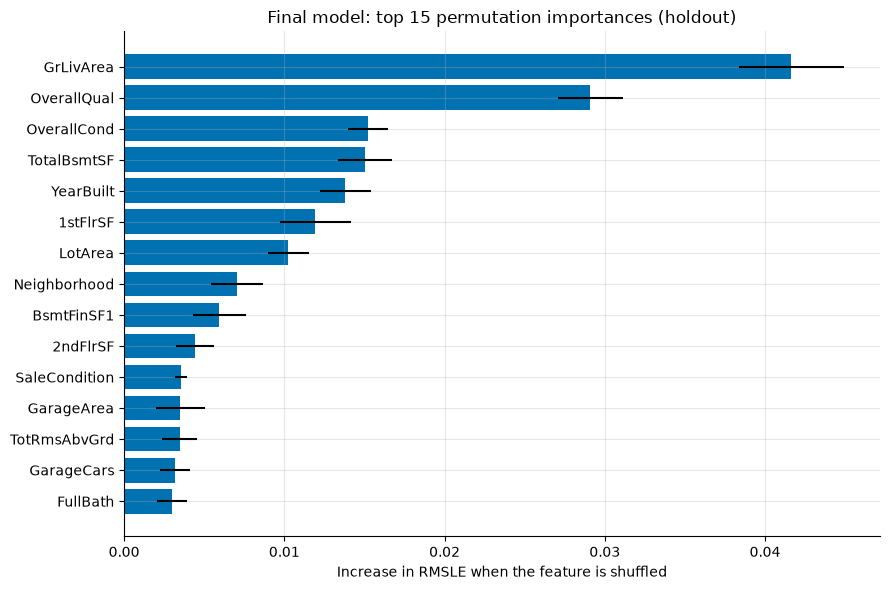

In [32]:
permutation = permutation_importance(holdout_model, X_valid, y_valid, scoring=rmsle_scorer,
                                     n_repeats=5, random_state=RANDOM_STATE, n_jobs=1)
importance = pd.DataFrame({
    "Feature": X_valid.columns,
    "RMSLE increase": permutation.importances_mean,
    "std": permutation.importances_std,
}).sort_values("RMSLE increase", ascending=False).head(15)

fig, ax = plt.subplots(figsize=(9, 6))
ax.barh(importance["Feature"], importance["RMSLE increase"], xerr=importance["std"], color=MAIN_COLOR)
ax.invert_yaxis()
ax.set_title("Final model: top 15 permutation importances (holdout)")
ax.set_xlabel("Increase in RMSLE when the feature is shuffled")
plt.tight_layout()
plt.show()

**Reading the importances.** Living area (`GrLivArea`) matters most by far, followed by overall quality. Then come condition, age (`YearBuilt`), basement size, lot size, and the neighborhood. These are the factors an appraiser would look at, a good sign that the model learned real structure rather than artefacts of the cleaning. `SaleCondition` also appears in the top 15: one of the factors behind the largest errors in section 12.

### Submission

The final configuration is refitted on **all labelled data** (outliers removed), so it learns from 25% more houses. Every learned value (medians, category lists, model weights) comes from labelled data only; the cleaned test set only goes through `predict()`.

In [33]:
full_train = train_clean.loc[~is_outlier(train_clean)]
final_model = clone(final_model_spec).fit(
    make_features(full_train), full_train["SalePrice"], sample_weight=unusual_sale_weights(full_train)
)

submission = pd.DataFrame({"Id": test_clean["Id"], "SalePrice": final_model.predict(X_test)})

# Kaggle expects the columns Id and SalePrice, one row per test house in test.csv order
assert list(submission.columns) == ["Id", "SalePrice"]
assert submission["Id"].equals(test_raw["Id"]) and submission["Id"].is_unique
assert submission["SalePrice"].notna().all() and (submission["SalePrice"] > 0).all()

submission.to_csv(DATA_DIR / "submission.csv", index=False)
print("Saved submission.csv:", submission.shape)
submission["SalePrice"].describe().loc[["min", "50%", "max"]].to_frame().style.format("${:,.0f}")

Saved submission.csv: (1459, 2)


,SalePrice
min,"$44,189"
50%,"$157,548"
max,"$789,159"


## 15. Summary

| Question | Answer |
|---|---|
| How are missing values handled? | By meaning: confirmed absence gets its own category, unknown information is labelled `"Unknown"` or imputed inside the pipeline, and not-applicable values get the house's own year plus an indicator. |
| Best way to fill `LotFrontage`? | A small model on `log(LotArea)` and lot categories guesses 30% better than neighborhood medians, but the effect on price predictions is negligible. |
| Can a model select features by itself? | Yes. Lasso uses 105 of 256 encoded features and matches Ridge and ElasticNet. Correlated features are handled by the penalty, so PCA is not needed. |
| Best model type? | Regularised linear models and gradient boosting, 14–16% better than the Random Forest. A blend of the two is better still. |
| Does classifying price tiers first help? | No. With fixed tiers (\$100k / \$300k) the classifier misses 44% of low-price and 35% of high-price houses, and the result is at best equal to the plain Random Forest. Changing the model type removes the bias instead. |
| Is the Random Forest's extreme-price bias real? | Partly: about half of what the first plot showed is regression to the mean; the rest (+7% / −5%) is real and specific to the Random Forest. The selected model has no meaningful bias. |
| Why are houses above \$300k under-predicted? | Mostly regression to the mean: −6.0% when chosen by actual price, −2.2% (95% CI about −4.4% to 0%) when chosen by predicted price. A mild real lean remains at quality 9–10 and above 4,000 sq ft total floor area, where data is thinnest. Calibrating by quality improves the CV RMSLE by only 0.0003, in 3 of 5 folds, so it is not used. |
| Where does the remaining error come from? | Mostly unusual sales (noise the data cannot explain) and the commercial zone (too few houses). 2% of houses cause over a third of the squared error. |
| Which blend is selected? | Ridge + Gradient Boosting with equal weights. A learned blend of five models scores 0.0002 better, a tie, so the simpler model is chosen. |
| Does down-weighting unusual sales help? | Slightly: half weight improves CV RMSLE by 0.0014, consistently in all five folds. |

**Final model:** an equal-weight blend (in log space) of Ridge and Gradient Boosting, trained on log prices with unusual sales at half weight.

| Measure | Random Forest baseline | Final model |
|---|---|---|
| CV RMSLE | 0.1311 | 0.1054 |
| Holdout RMSLE | 0.1451 | 0.1273 |

**Output:** `submission.csv`, from the final model refitted on all labelled data.

**Limitations:**

- Prices of unusual sales and commercial-zone houses are hard to predict from house features alone; they cause most of the remaining error.
- The best houses (quality 9–10, above 4,000 sq ft total floor area) are under-predicted by about 4–7% on average, an estimate with wide uncertainty; with fewer than 50 such houses, neither extra features nor calibration improve the overall score reliably.
- With 1,460 labelled houses, differences below about 0.004 RMSLE cannot be told apart reliably, so the top blends are effectively tied.
- The `MSZoning` fill and the basement and garage-year rules affect only a few test houses and cannot be scored on labelled data.

**Kaggle result:** `submission.csv` scores an RMSLE of **0.1224** on the public leaderboard, rank 740 of 4,268. The leaderboard's top 59 scores are far below what any model reaches (rank 56: 0.032) and come from leaked test prices; excluding them, the model ranks about 681 of 4,209 (top 16%). The best score that looks leak-free is 0.1067, 0.016 below this model's.